# Dating Profile Intelligence: NLP Powered User Segmentation and Profile Similarity

A portfolio project using the OKCupid dating profiles dataset (`profiles.csv`).

**Answer:** Partly. Essays help predict drinking habits (test macro F1 0.386 against 0.212 for guessing) and find similar profiles slightly better than chance, but user segments are only weakly separated and nothing here shows that two people would match.

**Status:** All 15 sections are written. The slide deck link is a placeholder until the presentation exists.

**Contents**
1. Project Overview, Business Problem and Research Questions
2. Ethics, Privacy and Fairness
3. Environment Setup, Data Loading and Data Dictionary
4. Data Quality Assessment and Train Test Split
5. Exploratory Data Analysis
6. Statistical Analysis and Hypothesis Testing
7. Feature Engineering and Preprocessing
8. NLP and Text Representation
9. User Segmentation and Clustering
10. Supervised Learning: Predicting drinks
11. Profile Similarity System
12. Model Evaluation, Baseline Comparison and Results
13. Business Insights and Product Recommendations
14. Conclusions, Model Card and Limitations
15. Future Work and Portfolio Presentation

## 1. Project Overview, Business Problem and Research Questions

Frames the project: why it matters, what it will deliver and the questions it will answer.

### 1.1 Introduction

Dating apps rely on profile information to introduce users to people they may like. Each OkCupid profile combines multiple choice answers, such as drinking habits, diet and education, with ten short essay prompts written in the user's own words.

This project uses that dataset, 59,946 profiles and 31 columns, to study how structured answers and free text can be used to group users, predict a missing answer and find similar profiles.

### 1.2 Business problem

When a new user joins, the app has no record of who they view, message or match with. It has only the profile, and many profiles are incomplete. Recommendations for new users therefore depend on how well the app can read the profile text and fill gaps in the structured answers. This is known as the cold start problem.

Drinking habits are a useful example. Lifestyle compatibility often decides whether two people are a good fit, and the `drinks` answer is missing for 5% of profiles. A reliable estimate of a missing answer would give a new user better recommendations from the first day.

### 1.3 Objectives

1. **Segmentation.** Identify groups of users from their essays and lifestyle answers, and describe each group in plain language.
2. **Prediction.** Build a classifier for `drinks`, grouped into four levels, and compare it with a baseline that always predicts the most common answer.
3. **Similarity.** Build a profile similarity search and compare two text representations, TF-IDF and sentence embeddings.
4. **Responsible practice.** Document the ethical limits of the data and keep the workflow reproducible, with fixed random seeds and a held out test set.

The project succeeds if each question receives a clear answer supported by evidence, including a plain statement where the evidence is weak.

### 1.4 Research questions

**Question 1. User segmentation.** Can meaningful user groups be discovered from profile descriptions, interests and lifestyle information?

* Method: clustering on text and lifestyle features.
* Evidence: a segment is meaningful if it is stable across random seeds, separated from the others by silhouette score, and can be described clearly. Differences in `drinks` between segments are used to check the groups, never to build them.

**Question 2. Supervised learning.** Can drinking preferences be predicted from other profile attributes, and does clustering improve predictive performance?

* Method: classification models compared with a baseline, with and without segment features.
* Evidence: macro F1 on a held out test set, with uncertainty ranges.

**Question 3. Profile similarity.** Can NLP identify profiles with similar characteristics, and how do TF-IDF and sentence embeddings compare?

* Method: nearest neighbour search with cosine similarity on each representation.
* Evidence: hide a field from a profile and measure how often its nearest neighbours share it. Both representations are scored the same way.

### 1.5 Scope and data limits

**In scope**
* All 59,946 profiles for exploration and text analysis.
* The 56,961 profiles with a `drinks` answer for supervised modelling.
* The ten essay fields and the structured answers, used for clustering, classification and similarity search.

**Out of scope**
* Predicting orientation, religion or ethnicity. See Section 2.
* Match, message or swipe outcomes, which the data does not contain.
* Deploying a model or building an application.

**What the data cannot tell us**
* **Age of the data.** Profiles were last online between June 2011 and July 2012, so patterns may not match current users.
* **Geography.** Almost all profiles, 59,855 of 59,946, are in California, and about half mention San Francisco.
* **Self reported answers.** Users describe themselves, and nothing is verified.
* **Selected users.** The data covers one app and its users, not the wider population.
* **Gender coding.** `sex` has two values, male and female, so the dataset cannot support conclusions about other identities.
* **No outcomes.** Without matches, the similarity system can only be evaluated with proxy measures, not by whether people actually liked each other.

## 2. Ethics, Privacy and Fairness

States how the data is handled and where the project draws its limits.

### 2.1 Origin of the data and consent

The file `profiles.csv` appears to be the educational dataset "San Francisco OKCupid Users", created by Albert Y. Kim and Adriana Escobedo-Land of Reed College and published with a 2015 journal paper. It holds 59,946 public profiles, scraped from the site on 30 June 2012 within 25 miles of San Francisco. The match rests on the user count, the date and the area. I did not compare the files directly.

According to the dataset's documentation, OkCupid gave permission to use the data, on the condition that the dataset remains public. No page states a licence, and none says that the users themselves were asked or agreed. The authors later published a revised version that removes `location` and `last_online`, adds noise to age and shuffles the essays so that they no longer match the profiles. This project uses the original version, which still has those links. A different release of about 70,000 profiles in 2016 was widely criticised for exposing personal information, and OkCupid said it broke its terms. It is a separate dataset, but it shows why this kind of data needs care.

Permission from a platform is not consent from the people in the data. For that reason this project:
* is for education and a portfolio only, and the data is not redistributed;
* makes no attempt to identify any individual;
* treats the findings as patterns in a group, not facts about a person.

### 2.2 Privacy and the risk of identifying individuals

The file has no usernames or ID columns, but that does not make it anonymous. Two checks on the data show why.

**Personal details in the essays.** A pattern search finds contact details written into the free text, which means some essays name or point to a real person.
* Web links: about 3,500 profiles
* Social media handles: about 80 profiles
* Email addresses: about 60 profiles
* Phone numbers: about 10 profiles

These counts come from simple patterns and are approximate.

**Ordinary fields can single people out.** Among profiles with `age`, `sex`, `location`, `height`, `job` and `education` all filled in, 64% have a combination that no other profile shares. Even with only `age`, `sex`, `location` and `height`, 16.5% of profiles are unique. Anyone who knows these details about a person could find the matching row.

**Handling rules**
* Links, handles, emails and phone numbers are removed from the essays before any text analysis.
* No raw essay text is printed or plotted. Outputs show counts, scores and word level patterns across many profiles.
* `profiles.csv` stays out of version control.

Section 3.6 reproduces these figures from the data.

### 2.3 Sensitive attributes

Some columns describe protected or sensitive characteristics, especially `orientation`, `religion` and `ethnicity`. Others, such as `drugs` and `income`, are also private.

**Decisions**
* No sensitive attribute is used as a prediction target. The target is `drinks`.
* `orientation`, `religion` and `ethnicity` are not used as model inputs. This reduces the chance that the models rely on them directly.
* These columns are still described in the data dictionary, so the exclusion is visible and deliberate.

**A known limit.** Essays and lifestyle answers can reveal these traits indirectly, and published work has shown that profile text can expose demographic attributes. Removing the columns lowers the risk but does not remove it. For that reason, no result in this project is presented as a way to infer a person's orientation, religion or ethnicity.

### 2.4 Fairness and bias in segmentation and similarity

The dataset is not a balanced sample of people, and this affects every model built from it.

* **Skewed sample.** About 60% of profiles are male and nearly all are from California. Segments and models will mostly reflect that group.
* **Uneven text.** Users write different amounts, and some write in other languages or leave essays blank. Text models may work worse for them.
* **Similarity can narrow choices.** A system that returns profiles like the one a user wrote may keep showing people who look alike, which limits variety.
* **Errors may not be spread evenly.** A model can score well overall and still do worse for one group.

**Planned checks**
* Report model performance separately by `sex` and by age band in Section 12.
* Compare performance for short essays and long essays.
* Describe segments by their content, not by demographic labels, and say in the conclusions where a segment mostly reflects one group.

### 2.5 Reporting principles

1. Report aggregate results only. Do not show individual profile text.
2. Quote no essays. Where an example is needed, describe it in general terms.
3. State limits next to every headline result.
4. Do not present similarity or segment results as a measure of compatibility, since the data contains no match outcomes.
5. Do not publish `profiles.csv` or any file derived from it that contains profile level text.
6. Record any change to these rules in this section.

## 3. Environment Setup, Data Loading and Data Dictionary

Sets up a reproducible environment, loads the raw file and documents every column.

### 3.1 Imports and reproducibility settings

Libraries, package versions and the random seed.

Versions are printed so the run can be repeated. Libraries for the text work, such as the sentence embedding model, are added in Section 8.

In [1]:
import html
import random
import re
import sys
import time
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib.externals.loky import get_reusable_executor
from scipy import stats
from sentence_transformers import SentenceTransformer
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import NMF, PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, classification_report, confusion_matrix, f1_score, recall_score, silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid")

print("Python", sys.version.split()[0])
for package in ["pandas", "numpy", "scikit-learn", "matplotlib", "seaborn", "scipy", "sentence-transformers"]:
    print(f"{package:<14}{version(package)}")

W1114 16:27:21.466000 60362 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Python 3.12.15
pandas        3.1.1
numpy         2.5.4
scikit-learn  1.9.1
matplotlib    3.11.2
seaborn       0.13.2
scipy         1.18.1
sentence-transformers6.3.0


### 3.2 Parameters

File paths, the seed and column lists in one place.

In [2]:
# Parameters used throughout the notebook
DATA_PATH = Path("profiles.csv")
RANDOM_STATE = 42
TARGET_RAW = "drinks"
TARGET = "drinks_level"
TEST_SIZE = 0.2

ESSAY_COLUMNS = [f"essay{i}" for i in range(10)]
SENSITIVE_COLUMNS = ["orientation", "religion", "ethnicity"]

# Columns summarised by their most common answers in section 3.4: none holds free text or a location
DISPLAY_COLUMNS = ["body_type", "diet", "drinks", "drugs", "education", "pets", "smokes", "status"]

# Settings for the statistical tests in section 6
ALPHA = 0.05
N_BOOTSTRAPS = 200

# Settings for the text work in section 8
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
TFIDF_MIN_DOCS = 10
TFIDF_MAX_FEATURES = 20000
N_TOPICS = 8

# Common first names, hidden from the word lists shown in sections 8 and 9. This affects the display only.
PERSONAL_NAMES = set("""
aaron adam adrian alex alexander alicia amanda amy andrea andrew andy angela anna anne anthony
ashley becky ben benjamin bob brad brandon brian brittany carlos chad charles charlie chris
christina christine christopher courtney dan daniel danielle david dennis derek diana doug
douglas edward elizabeth emily eric erica erin frank gary george greg gregory hannah heather
henry ian jackie jacob james jason jeff jeffrey jen jennifer jenny jerry jess jesse jessica
jim jimmy joe john jon jonathan jose joseph josh joshua juan julia julie justin karen kate
katherine kathy katie kelly ken kenneth kevin kim kimberly kristen kristin kyle larry laura
lauren lindsay lindsey lisa liz luis luke marcus maria mary matt matthew megan melissa michael
michelle mike monica natalie nicholas nick nicole nina olivia oscar patricia patrick paul
peter rachel rebecca rob robbie robert ryan sam samantha samuel sara sarah scott sean sophia
stephanie stephen steve steven susan thomas tiffany tim timothy tom tony vanessa veronica
victor victoria vincent walter wendy yvonne
""".split())

# Settings for the segmentation in section 9
TEXT_COMPONENTS = 20
LIFESTYLE_COMPONENTS = 15
N_CLUSTERS = 6  # chosen in section 9.3
SILHOUETTE_SAMPLE = 10000

# Settings for the models in section 10
N_FOLDS = 5
N_JOBS = 5  # folds fitted at the same time, one per fold. Each worker needs about 2 GB, so lower it on a computer with little memory.
LOGISTIC_MAX_ITER = 3000  # iteration limit of the logistic regression solver

# Settings for the similarity system in section 11
SIMILARITY_QUERIES = 5000
N_NEIGHBOURS = 10

# Setting for the final evaluation in section 12
N_TEST_BOOTSTRAPS = 1000

# Chart settings. Drinking habits run from least to most, so one blue ramp from light to dark.
CLASS_ORDER = ["not at all", "rarely", "socially", "often+"]
CLASS_COLORS = ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]
BAR_COLOR = CLASS_COLORS[2]

# Target levels. The rare answers "very often" and "desperately" are merged with "often" (see section 4.5).
DRINKS_LEVELS = {
    "not at all": "not at all",
    "rarely": "rarely",
    "socially": "socially",
    "often": "often+",
    "very often": "often+",
    "desperately": "often+",
}

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

### 3.3 Load the data

Read `profiles.csv` into `df_raw`, which is never overwritten.

**Finding.** The file holds 59,946 rows and 31 columns: 21 structured fields and 10 essays. `df_raw` is not changed anywhere in the notebook.

In [3]:
df_raw = pd.read_csv(DATA_PATH)
print(f"{df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

59,946 rows x 31 columns


### 3.4 Initial inspection

Shape, column types, and the most common answers in a few columns.

**Finding.** 28 columns are text, `age` and `income` are integers and `height` is a decimal. Essay answers range from 40,721 profiles for `essay8` to 54,458 for `essay0`, and median length ranges from 54 characters for `essay3` to 479 for `essay0`. Essay text and individual rows are not displayed, in line with Section 2. A few columns are summarised by their most common answers instead.

In [4]:
# One row per column: its type, how many values are filled in, and how many different values it holds
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "non_null": df_raw.notna().sum(),
    "unique": df_raw.nunique(),
})
print(f"Memory: {df_raw.memory_usage(deep=True).sum() / 1e6:.0f} MB\n")
overview

Memory: 225 MB



,dtype,non_null,unique
age,int64,59946,54
body_type,str,54650,12
diet,str,35551,18
drinks,str,56961,6
drugs,str,45866,3
education,str,53318,32
essay0,str,54458,54350
essay1,str,52374,51516
essay2,str,50308,48635
essay3,str,48470,43533


In [5]:
# Essay text is never printed. Count how many users answered each prompt and how long a typical answer is.
essay_summary = pd.DataFrame({
    "answered": df_raw[ESSAY_COLUMNS].notna().sum(),
    "median_characters": df_raw[ESSAY_COLUMNS].apply(lambda column: column.str.len()).median(),
})
essay_summary

,answered,median_characters
essay0,54458,479.0
essay1,52374,182.0
essay2,50308,116.0
essay3,48470,54.0
essay4,49409,472.0
essay5,49096,104.0
essay6,46175,87.0
essay7,47495,88.0
essay8,40721,60.0
essay9,47343,113.0


In [6]:
# The most common answers in a few columns that hold no free text. No individual rows are shown.
for column in DISPLAY_COLUMNS:
    shares = df_raw[column].value_counts(normalize=True)
    top_answers = ", ".join(f"{answer} {share:.0%}" for answer, share in shares.head(3).items())
    print(f"{column:<10} most common: {top_answers} | blank: {df_raw[column].isna().mean():.0%}")

body_type  most common: average 27%, fit 23%, athletic 22% | blank: 9%
diet       most common: mostly anything 47%, anything 17%, strictly anything 14% | blank: 41%
drinks     most common: socially 73%, rarely 10%, often 9% | blank: 5%
drugs      most common: never 82%, sometimes 17%, often 1% | blank: 23%
education  most common: graduated from college/university 45%, graduated from masters program 17%, working on college/university 11% | blank: 11%
pets       most common: likes dogs and likes cats 37%, likes dogs 18%, likes dogs and has cats 11% | blank: 33%
smokes     most common: no 81%, sometimes 7%, when drinking 6% | blank: 9%
status     most common: single 93%, seeing someone 3%, available 3% | blank: 0%


### 3.5 Data dictionary

Name, type, meaning and role of each column, written after inspection.

**Finding.** Of the 31 columns, 10 are essays, 3 are excluded as sensitive, 1 is the source of the target and 1 is not used because a new user has no activity record. The remaining 16 are candidate features, to be reviewed in Sections 5 to 7.

In [7]:
# Descriptions are written from the column names and the values seen in the data, not copied from the
# codebook that the dataset's authors published. Each row is: column, description, role in this project.
rows = [
    ("age", "Age in years", "candidate feature"),
    ("body_type", "Self described body type", "candidate feature"),
    ("diet", "Diet and how strictly it is followed", "candidate feature"),
    ("drinks", "Drinking habits", "target source"),
    ("drugs", "Drug use", "candidate feature"),
    ("education", "Education level and status", "candidate feature"),
    ("ethnicity", "Self reported ethnicity", "excluded, sensitive"),
    ("height", "Height in inches", "candidate feature"),
    ("income", "Stated income, with -1 appearing for most profiles", "candidate feature"),
    ("job", "Occupation category", "candidate feature"),
    ("last_online", "Date and time of last login, stored as text", "not used, absent for a new user"),
    ("location", "City and state, stored as text", "candidate feature"),
    ("offspring", "Children: current status and wishes", "candidate feature"),
    ("orientation", "Sexual orientation", "excluded, sensitive"),
    ("pets", "Attitude to pets and pets owned", "candidate feature"),
    ("religion", "Religion and how seriously it is held", "excluded, sensitive"),
    ("sex", "Male or female", "candidate feature, also used for fairness checks"),
    ("sign", "Zodiac sign and attitude to it", "candidate feature"),
    ("smokes", "Smoking habits", "candidate feature"),
    ("speaks", "Languages spoken, with fluency", "candidate feature"),
    ("status", "Relationship status", "candidate feature"),
]

essay_prompts = [
    "My self summary",
    "What I am doing with my life",
    "I am really good at",
    "The first thing people usually notice about me",
    "Favorite books, movies, shows, music and food",
    "The six things I could never do without",
    "I spend a lot of time thinking about",
    "On a typical Friday night I am",
    "The most private thing I am willing to admit",
    "You should message me if",
]
for number, prompt in enumerate(essay_prompts):
    rows.append((f"essay{number}", f"Essay prompt: {prompt}", "essay text"))

data_dictionary = pd.DataFrame(rows, columns=["column", "description", "role"]).set_index("column")

# Every column in the data must appear in the dictionary
assert set(data_dictionary.index) == set(df_raw.columns)

# Add the type and number of different values, taken from the data
data_dictionary["dtype"] = df_raw.dtypes.astype(str)
data_dictionary["unique"] = df_raw.nunique()
data_dictionary = data_dictionary[["dtype", "unique", "description", "role"]]

print(data_dictionary["role"].value_counts().to_string())
data_dictionary

role
candidate feature                                   15
essay text                                          10
excluded, sensitive                                  3
target source                                        1
not used, absent for a new user                      1
candidate feature, also used for fairness checks     1


,dtype,unique,description,role
column,,,,
age,int64,54,Age in years,candidate feature
body_type,str,12,Self described body type,candidate feature
diet,str,18,Diet and how strictly it is followed,candidate feature
drinks,str,6,Drinking habits,target source
drugs,str,3,Drug use,candidate feature
education,str,32,Education level and status,candidate feature
ethnicity,str,217,Self reported ethnicity,"excluded, sensitive"
height,float64,60,Height in inches,candidate feature
income,int64,13,"Stated income, with -1 appearing for most profiles",candidate feature


### 3.6 Reproducing the privacy figures from Section 2

Counts of personal details in the essays are approximate because they use simple text patterns. Counts of unique field combinations are exact. Only counts are printed.

In [8]:
# Reproduces the privacy figures in section 2.2. Run after section 3.3.
# Only counts are printed, never text.

# Part 1: personal details written in the essays. Simple patterns make these counts approximate.
essay_text = df_raw[ESSAY_COLUMNS].fillna("").agg(" ".join, axis=1)
patterns = {
    "web link": r"https?://|www\.",
    "social media handle": r"(?<!\w)@\w{3,}",
    "email address": r"[\w.+]+@\w+\.[a-z]{2,}",
    "phone number": r"\(?\d{3}\)?[\s.]\d{3}[\s.]\d{4}",
}
for name, pattern in patterns.items():
    count = essay_text.str.contains(pattern, case=False).sum()
    print(f"{name:<20}{count:>6,} profiles (approximate)")
del essay_text

# Part 2: how many profiles have a combination of fields that no other profile shares. These counts are exact.
six_fields = ["age", "sex", "location", "height", "job", "education"]
four_fields = ["age", "sex", "location", "height"]
for fields in (six_fields, four_fields):
    complete = df_raw[fields].dropna()
    is_unique = ~complete.duplicated(keep=False)
    print(f"\n{len(fields)} fields: {is_unique.sum():,} of {len(complete):,} complete profiles are unique ({is_unique.mean():.1%})")

web link             3,485 profiles (approximate)


social media handle     83 profiles (approximate)


email address           63 profiles (approximate)


phone number            11 profiles (approximate)

6 fields: 30,977 of 48,175 complete profiles are unique (64.3%)

4 fields: 9,861 of 59,943 complete profiles are unique (16.5%)


## 4. Data Quality Assessment and Train Test Split

Checks the data for problems, then splits it so that every later step is fitted on training data only.

### 4.1 Missing values and placeholder answers

Two kinds of missing data are checked. Blank values are counted directly. Hidden missing codes are values that stand for "no answer". They are found by scanning every text column for placeholder wording and by inspecting `income`.

`other` in `diet`, `ethnicity`, `job` and `religion` is a genuine answer and is not treated as missing.

**Finding.** `offspring` (59.3%), `diet` (40.7%) and `religion` (33.7%) have the most blank values. `income` has no blanks, but it holds -1 for 80.8% of profiles, which means no answer was given. It is therefore the most incomplete field in the data. Smaller placeholder codes appear in `status` and, as "rather not say", in `body_type` and `job`.

In [9]:
# Part 1: blank values in each column
blank_count = df_raw.isna().sum()
blank_table = pd.DataFrame({
    "missing": blank_count,
    "missing_pct": (blank_count / len(df_raw) * 100).round(1),
})
blank_table = blank_table[blank_table["missing"] > 0].sort_values("missing_pct", ascending=False)
print(blank_table.to_string())

# Part 2: scan the text columns (essays excluded) for words that mean "no answer"
placeholder_words = ["unknown", "n/a", "none", "null", "rather not say"]
text_columns = [
    column for column in df_raw.columns
    if column not in ESSAY_COLUMNS and not pd.api.types.is_numeric_dtype(df_raw[column])
]
print("\nPlaceholder wording found")
for column in text_columns:
    values = df_raw[column].dropna().str.strip().str.lower()
    found = values[values.isin(placeholder_words)].value_counts()
    if not found.empty:
        print(f"  {column}: {found.to_dict()}")

# Part 3: values that stand for "no answer", decided from the checks above
HIDDEN_CODES = [
    ("income", -1),
    ("status", "unknown"),
    ("body_type", "rather not say"),
    ("job", "rather not say"),
]
print("\nHidden missing codes")
for column, value in HIDDEN_CODES:
    count = (df_raw[column] == value).sum()
    print(f"  {column:<10}{str(value):<16}{count:>7,} profiles ({count / len(df_raw):.1%})")

           missing  missing_pct
offspring    35561         59.3
diet         24395         40.7
religion     20226         33.7
pets         19921         33.2
essay8       19225         32.1
drugs        14080         23.5
essay6       13771         23.0
essay9       12603         21.0
essay7       12451         20.8
essay3       11476         19.1
sign         11056         18.4
essay5       10850         18.1
essay4       10537         17.6
essay2        9638         16.1
job           8198         13.7
essay1        7572         12.6
education     6628         11.1
ethnicity     5680          9.5
essay0        5488          9.2
smokes        5512          9.2
body_type     5296          8.8
drinks        2985          5.0
speaks          50          0.1
height           3          0.0

Placeholder wording found
  body_type: {'rather not say': 198}
  job: {'rather not say': 436}


  status: {'unknown': 10}

Hidden missing codes
  income    -1               48,442 profiles (80.8%)
  status    unknown              10 profiles (0.0%)
  body_type rather not say      198 profiles (0.3%)
  job       rather not say      436 profiles (0.7%)


### 4.2 Duplicates and invalid values

Duplicates matter for the split. If the same profile appeared in both training and test data, the test score would be inflated. Impossible values are found by checking each numeric field against a plausible range: age 18 to 100, and height 48 to 84 inches (4 to 7 feet).

**Finding.** No row is an exact duplicate. 108 profiles repeat the first essay of another profile, which is too few to change results, and it is noted as a small leakage risk. Age is invalid for 2 profiles (109 and 110) and height for 59.

In [10]:
VALID_RANGES = {"age": (18, 100), "height": (48, 84)}

print(f"Exact duplicate rows: {df_raw.duplicated().sum()}")

first_essay = df_raw["essay0"].dropna().str.strip()
first_essay = first_essay[first_essay != ""]
print(f"Profiles repeating another profile's first essay: {first_essay.duplicated().sum()}")

print("\nValues outside the plausible range")
for column, (low, high) in VALID_RANGES.items():
    values = df_raw[column].dropna()
    print(f"  {column} ({low} to {high}): {(~values.between(low, high)).sum()} profiles, "
          f"observed {values.min():g} to {values.max():g}")

Exact duplicate rows: 0
Profiles repeating another profile's first essay: 108

Values outside the plausible range
  age (18 to 100): 2 profiles, observed 18 to 110
  height (48 to 84): 59 profiles, observed 1 to 95


### 4.3 Quality of the essay text

Essays are counted, never displayed. The checks cover blank essays, very short essays and web markup left in the text.

**Finding.** 2,124 profiles wrote no essay at all, and between 232 and 3,259 essays per prompt are under 10 characters, so many answers carry little text. Markup is common: HTML tags appear in 32,029 first essays and 36,983 answers to the favorites prompt (`essay4`), and HTML entities in 3,170 and 9,458 of them. This is cleaned in Section 8. A simple rule cannot reliably detect non English text, so that remains an unmeasured limit.

In [11]:
essays = df_raw[ESSAY_COLUMNS]

# Answer length in characters. Unanswered essays have no length, so they are never counted as short.
lengths = essays.apply(lambda column: column.str.strip().str.len())

essay_quality = pd.DataFrame({
    "missing": essays.isna().sum(),
    "under_10_characters": (lengths < 10).sum(),
    "with_html_tag": essays.apply(lambda column: column.str.contains(r"<[a-z/]", case=False, na=False)).sum(),
    "with_html_entity": essays.apply(lambda column: column.str.contains(r"&[a-z#0-9]+;", case=False, na=False)).sum(),
})
print(essay_quality.to_string())

# No essay is blank but present, so a profile with no essay text is one where all ten are missing
no_essay = essays.isna().all(axis=1).sum()
print(f"\nProfiles with no essay text at all: {no_essay:,}")

        missing  under_10_characters  with_html_tag  with_html_entity
essay0     5488                  263          32029              3170
essay1     7572                  495          15216              1581
essay2     9638                 1014          14369              1143
essay3    11476                 3259           6387               574
essay4    10537                  232          36983              9458
essay5    10850                  265          30807              2977
essay6    13771                 1484          10767               878
essay7    12451                 1056           5532               678
essay8    19225                 1006           5483               465
essay9    12603                  270          14160              1084

Profiles with no essay text at all: 2,124


### 4.4 Applying the cleaning rules

The rules below are fixed in advance and learn nothing from the data, so applying them to every profile cannot leak information between the training and test sets. Rules that depend on the data, such as imputation and scaling, wait until Section 7 and are fitted on the training set only.

1. Hidden missing codes from 4.1 become missing values.
2. Ages outside 18 to 100 and heights outside 48 to 84 inches become missing values.
3. HTML entities in `offspring` and `sign` are decoded, for example `&rsquo;` becomes an apostrophe.

Essay text is left as written until Section 8. `df_raw` is not changed. The cleaned copy is `df_clean`.

**Implication.** `income` is now 80.8% missing, so it will be a weak feature and may be dropped or reduced to an answered or not answered flag. Setting invalid values to missing keeps the profile in the data and avoids guessing a correction.

In [12]:
HTML_COLUMNS = ["offspring", "sign"]


def clean_profiles(df):
    """Apply fixed cleaning rules that learn nothing from the data."""
    out = df.copy()
    for (column, value) in HIDDEN_CODES:
        out[column] = out[column].mask(out[column] == value)
    for column, (low, high) in VALID_RANGES.items():
        out[column] = out[column].where(out[column].between(low, high))
    for column in HTML_COLUMNS:
        out[column] = out[column].map(html.unescape, na_action="ignore")
    return out


df_clean = clean_profiles(df_raw)

newly_missing = (df_raw.notna() & df_clean.isna()).sum()
print("Values set to missing")
print(newly_missing[newly_missing > 0].to_string())
for column in HTML_COLUMNS:
    changed = (df_raw[column].notna() & (df_raw[column] != df_clean[column])).sum()
    print(f"HTML entities decoded in {column}: {changed:,} values")

# df_raw must be untouched
assert df_raw.shape == df_clean.shape
assert (df_raw["income"] == -1).any()

Values set to missing
age              2
body_type      198
height          59
income       48442
job            436
status          10
HTML entities decoded in offspring: 19,776 values
HTML entities decoded in sign: 36,091 values


### 4.5 Target definition

The target is `drinks`, grouped into four levels. "very often" (0.8% of labelled profiles) and "desperately" (0.6%) are too rare to learn from, so they are merged with "often".

* not at all becomes **not at all**
* rarely becomes **rarely**
* socially becomes **socially**
* often, very often and desperately become **often+**

Profiles with no `drinks` answer cannot be used as labelled examples. They are kept in `df_unlabelled` for the clustering and similarity work in Sections 9 and 11, where no label is needed.

**Imbalance.** One class holds most of the data, so accuracy is misleading. A model that always predicts the most common answer sets the baseline, and models are compared on macro F1, which weights every class equally.

In [13]:
df_clean[TARGET] = df_clean[TARGET_RAW].map(DRINKS_LEVELS)
has_label = df_clean[TARGET].notna()
df_labelled = df_clean[has_label]
df_unlabelled = df_clean[~has_label]

counts = df_labelled[TARGET].value_counts()
class_table = pd.DataFrame({"count": counts, "share_pct": (counts / counts.sum() * 100).round(1)})
print(class_table.to_string())
print(f"\nLabelled profiles: {len(df_labelled):,} | without a drinks answer: {len(df_unlabelled):,}")
print(f"Largest class is {counts.max() / counts.min():.1f} times the smallest")

              count  share_pct
drinks_level                  
socially      41780       73.3
often+         5957       10.5
rarely         5957       10.5
not at all     3267        5.7

Labelled profiles: 56,961 | without a drinks answer: 2,985
Largest class is 12.8 times the smallest


### 4.6 Train test split

The labelled profiles are split once, with a fixed seed, stratified on the target so that every class has the same share in both parts. The test set is 20% of the labelled profiles.

**Rules from this point**
* Exploration, hypothesis tests, preprocessing and model fitting use the training set only.
* The test set is not used until the final evaluation in Section 12. Its class counts are printed once below, only to confirm the stratification.
* Profiles without a drinks answer join the training side for unsupervised fitting only, as `df_fit_unsupervised`. They are never used as labelled examples.
* The majority class is chosen from the training labels, and the baseline is scored on the training set here.

**Implication.** Clustering and the similarity index are fitted on training and unlabelled profiles. Test profiles are assigned to a cluster or searched against that index afterwards, never used to build them.

**Finding.** The class shares match between training and test to within 0.1 percentage points, so the stratification worked. The baseline that always predicts the most common answer reaches 0.733 accuracy but only 0.212 macro F1 on the training set. Those are the scores a model has to beat.

In [14]:
df_train, df_test = train_test_split(
    df_labelled,
    test_size=TEST_SIZE,
    stratify=df_labelled[TARGET],
    random_state=RANDOM_STATE,
)
df_fit_unsupervised = pd.concat([df_train, df_unlabelled])

# Checks: no overlap, and the same class shares in both parts
assert df_train.index.intersection(df_test.index).empty
assert df_fit_unsupervised.index.intersection(df_test.index).empty
shares = pd.DataFrame({
    "train_pct": (df_train[TARGET].value_counts(normalize=True) * 100).round(1),
    "test_pct": (df_test[TARGET].value_counts(normalize=True) * 100).round(1),
})
print(f"Train {len(df_train):,} | test {len(df_test):,} | unlabelled added for unsupervised work {len(df_unlabelled):,}")
print(shares.to_string())

# Majority class baseline, chosen and scored on the training set
majority = df_train[TARGET].value_counts().idxmax()
baseline = [majority] * len(df_train)
print(f"\nBaseline always predicts '{majority}' (training set)")
print(f"  accuracy {(df_train[TARGET] == majority).mean():.3f}")
print(f"  macro F1 {f1_score(df_train[TARGET], baseline, average='macro', zero_division=0):.3f}")

Train 45,568 | test 11,393 | unlabelled added for unsupervised work 2,985
              train_pct  test_pct
drinks_level                     
not at all          5.7       5.7
often+             10.5      10.5
rarely             10.5      10.5
socially           73.3      73.4

Baseline always predicts 'socially' (training set)


  accuracy 0.733
  macro F1 0.212


### 4.7 Data quality summary

* **Hidden missing codes.** `income` (80.8%), `status` (10 profiles) and "rather not say" in `body_type` (198) and `job` (436) become missing values. This makes `income` a weak feature.
* **Blank values.** `offspring`, `diet` and `religion` have the most. They are handled in Section 7 with rules fitted on the training set.
* **Duplicates.** No exact duplicates. 108 repeated first essays are kept and noted as a small risk.
* **Invalid values.** 2 ages and 59 heights become missing values. The profiles stay in the data.
* **Essay text.** 2,124 profiles have no essay, many answers are very short, and markup needs cleaning in Section 8.
* **Target.** Four levels, with the rare answers merged. 2,985 profiles have no label and are kept for the unsupervised work.
* **Split.** Stratified, seed 42, 80% training and 20% test. The test set stays untouched until Section 12.

Section 5 starts from `df_train`. `df_raw` has not been changed.

## 5. Exploratory Data Analysis

Describes the training data. Test data is not used in this section.

### 5.1 Target distribution

This section describes the **training set only**. A copy, `df_explore`, is used so that `df_train` stays exactly as it was split. Charts show the share of users in each drinking habit.

**Finding.** Almost three in four users say they drink socially, and each of the other three habits holds about one in ten users or fewer. The imbalance is the same as in the full data, so accuracy will be a poor measure and macro F1 remains the main score.

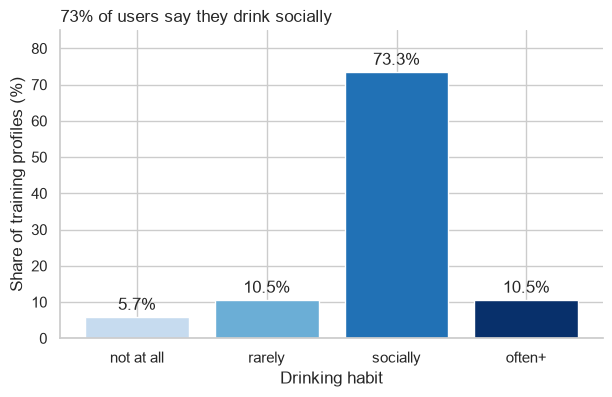

In [15]:
# Work on a copy so df_train stays exactly as split in section 4
df_explore = df_train.copy()

# No test profile may appear in the data we explore
assert not df_explore.index.isin(df_test.index).any()

class_share = df_explore[TARGET].value_counts(normalize=True)[CLASS_ORDER] * 100

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(CLASS_ORDER, class_share, color=CLASS_COLORS)
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in class_share], padding=3)
ax.set_title(f"{class_share['socially']:.0f}% of users say they drink socially", loc="left")
ax.set_xlabel("Drinking habit")
ax.set_ylabel("Share of training profiles (%)")
ax.set_ylim(0, 85)
sns.despine()
plt.show()

### 5.2 Numeric fields

Age, height and income are the numeric fields. The numbers come first, then charts of age and height. Income is mostly unanswered, so it is summarised in a table instead of a chart.

**Finding.** The typical user is in their late twenties or thirties and about 5 feet 8 inches tall. Only about one in five users gave an income, and among those who did, 20,000 is the most common answer.

In [16]:
print(df_explore[["age", "height"]].describe().round(1).to_string())

# Income is mostly a missing value after the cleaning in section 4
income_answers = df_explore["income"].value_counts().sort_index()
print(f"\nIncome was answered by {df_explore['income'].notna().mean():.1%} of profiles")
print(income_answers.to_string())

           age   height
count  45568.0  45533.0
mean      32.4     68.3
std        9.5      3.8
min       18.0     48.0
25%       26.0     66.0
50%       30.0     68.0
75%       37.0     71.0
max       69.0     84.0

Income was answered by 19.8% of profiles
income
20000.0      2331
30000.0       812
40000.0       788
50000.0       769
60000.0       577
70000.0       554
80000.0       868
100000.0     1281
150000.0      502
250000.0      112
500000.0       35
1000000.0     398


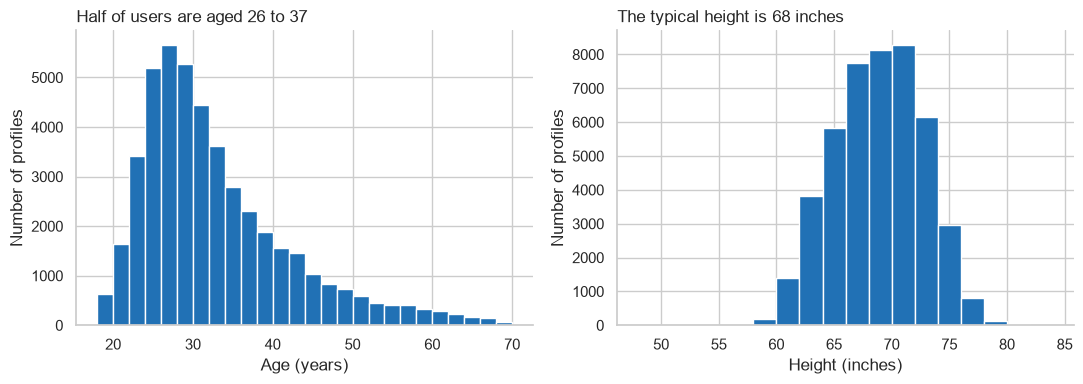

In [17]:
age_low, age_high = df_explore["age"].quantile([0.25, 0.75])
typical_height = df_explore["height"].median()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df_explore["age"].dropna(), bins=range(18, 71, 2), color=BAR_COLOR)
axes[0].set_title(f"Half of users are aged {age_low:.0f} to {age_high:.0f}", loc="left")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Number of profiles")

axes[1].hist(df_explore["height"].dropna(), bins=range(48, 86, 2), color=BAR_COLOR)
axes[1].set_title(f"The typical height is {typical_height:.0f} inches", loc="left")
axes[1].set_xlabel("Height (inches)")
axes[1].set_ylabel("Number of profiles")

sns.despine()
plt.tight_layout()
plt.show()

### 5.3 Categorical fields

For each categorical field the table shows how many different answers it has, the most common answer and its share, and how much is missing. `orientation`, `religion` and `ethnicity` are left out, as decided in Section 2.

**Finding.** Several fields are dominated by one answer: almost everyone is single, and most users do not smoke or use drugs. Some fields have many levels, such as `sign` (48) and `education` (32), and will need grouping in Section 7. `offspring`, `diet` and `pets` have the most missing answers.

In [18]:
categorical_columns = [
    "sex", "status", "smokes", "drugs", "diet", "body_type",
    "education", "job", "offspring", "pets", "sign", "location",
]

rows = []
for column in categorical_columns:
    counts = df_explore[column].value_counts()
    rows.append({
        "column": column,
        "levels": len(counts),
        "most_common": counts.index[0],
        "most_common_pct": round(counts.iloc[0] / counts.sum() * 100),
        "missing_pct": round(df_explore[column].isna().mean() * 100),
    })

pd.DataFrame(rows).set_index("column")

,levels,most_common,most_common_pct,missing_pct
column,,,,
sex,2,m,60,0
status,4,single,93,0
smokes,5,no,81,6
drugs,3,never,82,23
diet,18,mostly anything,47,39
body_type,11,average,27,8
education,32,graduated from college/university,45,10
job,20,other,15,13
offspring,15,doesn’t have kids,31,58


### 5.4 Essay completeness and length

Essays are measured, never displayed. The chart shows the share of users who answered each prompt, and the table shows how many prompts each user answered and how many words they wrote in total.

**Finding.** Most users answer most prompts, but the share varies by prompt, and some users wrote no essay at all. Total length differs a lot between users, from nothing to well over a thousand words, so text features will be uneven across the data.

       essays_answered  essay_words
count          45568.0      45568.0
mean               8.0        387.0
std                3.0        326.0
min                0.0          0.0
25%                7.0        175.0
50%               10.0        322.0
75%               10.0        519.0
max               10.0      12686.0


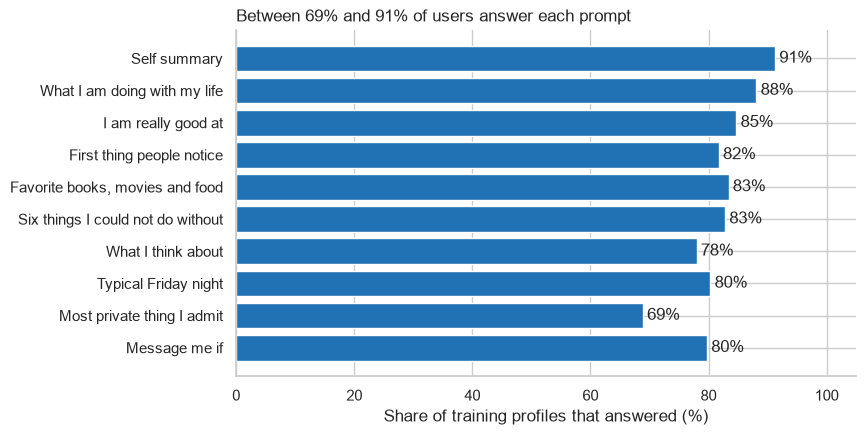

In [19]:
essays = df_explore[ESSAY_COLUMNS]

df_explore["essays_answered"] = essays.notna().sum(axis=1)
df_explore["essay_words"] = essays.fillna("").agg(" ".join, axis=1).str.split().str.len()
print(df_explore[["essays_answered", "essay_words"]].describe().round(0).to_string())

prompt_names = [
    "Self summary", "What I am doing with my life", "I am really good at",
    "First thing people notice", "Favorite books, movies and food", "Six things I could not do without",
    "What I think about", "Typical Friday night", "Most private thing I admit", "Message me if",
]
answered_share = essays.notna().mean() * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(prompt_names, answered_share.values, color=BAR_COLOR)
ax.bar_label(bars, labels=[f"{value:.0f}%" for value in answered_share], padding=3)
ax.invert_yaxis()
ax.set_xlim(0, 105)
ax.set_title(f"Between {answered_share.min():.0f}% and {answered_share.max():.0f}% of users answer each prompt", loc="left")
ax.set_xlabel("Share of training profiles that answered (%)")
sns.despine()
plt.show()

### 5.5 Relationships with drinks

Each chart splits one field into groups and shows how the users in each group answer the drinking question. Bars are shares of the group, so they add to 100%, and the number of users in each group is shown beside its name. Small groups give unreliable shares, so they are read with care. Differences here are descriptive. Section 6 tests which ones are real.

**Finding.** The clearest links are with drug use and smoking. Users who use drugs often, or who smoke, are much more likely to drink often. Users aged 45 and over are less likely to drink often and more likely to drink rarely or not at all. Men and women answer in a very similar way, and the length of a user's essays shows no clear link with drinking. This suggests that lifestyle answers will help a model, while essay length will not. Whether the essay content helps is tested in Sections 8 and 10.

In [20]:
def plot_drinks_by(column, title, order=None):
    """Show how each group in `column` answers the drinking question, as shares that add to 100%."""
    data = df_explore.dropna(subset=[column])
    group_sizes = data[column].value_counts()
    shares = pd.crosstab(data[column], data[TARGET], normalize="index")[CLASS_ORDER] * 100
    if order is not None:
        shares = shares.loc[order]
    shares.index = [f"{group} (n={group_sizes[group]:,})" for group in shares.index]

    ax = shares.plot(kind="barh", stacked=True, color=CLASS_COLORS, figsize=(9, 3.5), width=0.7, edgecolor="white")
    for position, container in enumerate(ax.containers):
        text_color = "black" if position < 2 else "white"
        labels = [f"{value:.0f}%" if value >= 4 else "" for value in container.datavalues]
        ax.bar_label(container, labels=labels, label_type="center", color=text_color, fontsize=9)

    ax.invert_yaxis()
    ax.set_title(title, loc="left")
    ax.set_xlabel("Share of users in the group (%)")
    ax.set_ylabel(column.replace("_", " ").capitalize())
    ax.legend(title="Drinking habit", ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
    sns.despine()
    plt.show()

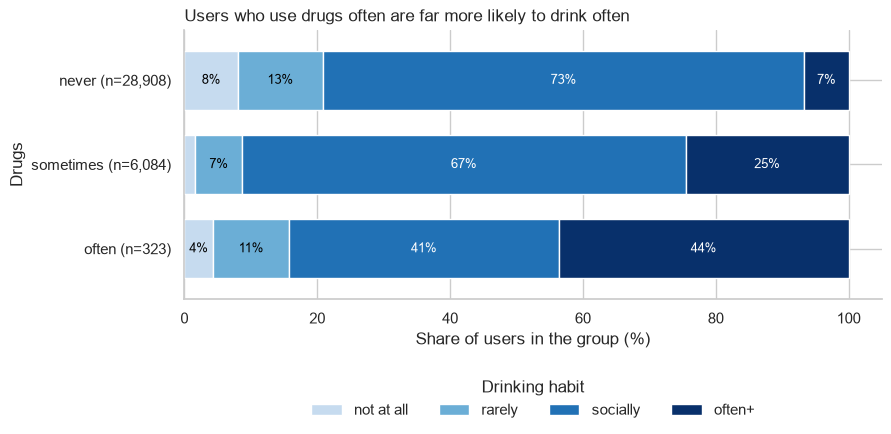

In [21]:
plot_drinks_by("drugs", "Users who use drugs often are far more likely to drink often", order=["never", "sometimes", "often"])

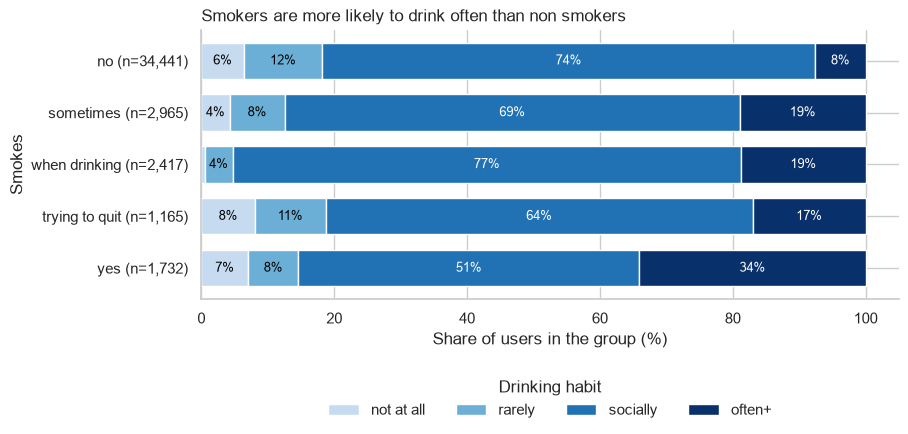

In [22]:
plot_drinks_by(
    "smokes",
    "Smokers are more likely to drink often than non smokers",
    order=["no", "sometimes", "when drinking", "trying to quit", "yes"],
)

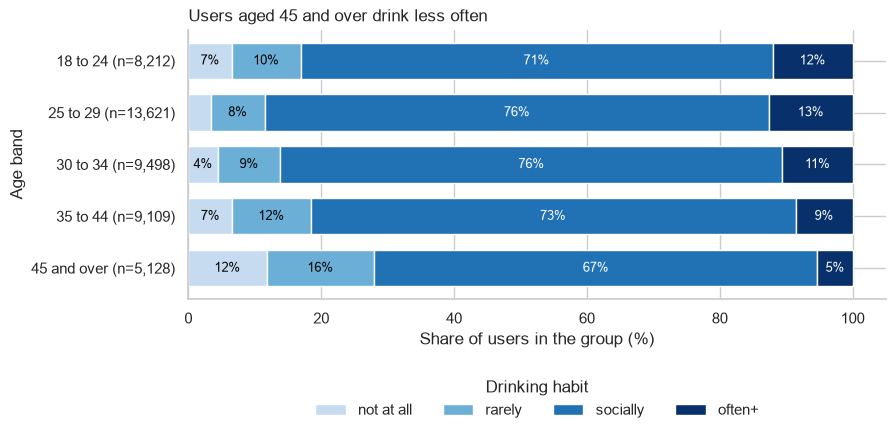

In [23]:
df_explore["age_band"] = pd.cut(
    df_explore["age"],
    bins=[17, 24, 29, 34, 44, 100],
    labels=["18 to 24", "25 to 29", "30 to 34", "35 to 44", "45 and over"],
)
plot_drinks_by("age_band", "Users aged 45 and over drink less often")

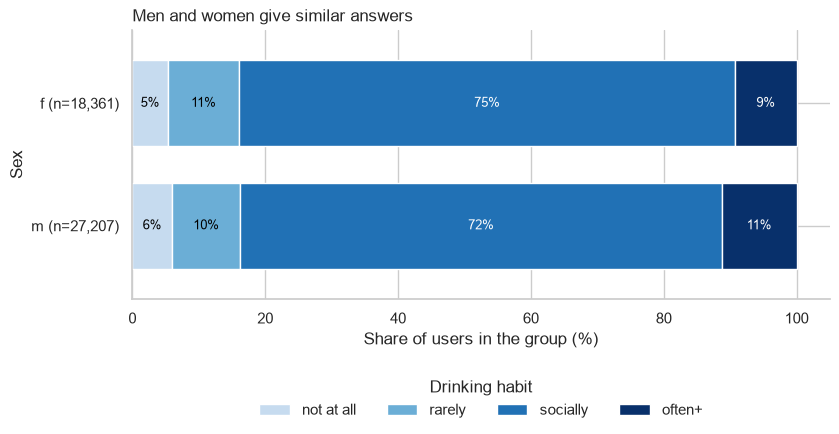

In [24]:
plot_drinks_by("sex", "Men and women give similar answers", order=["f", "m"])

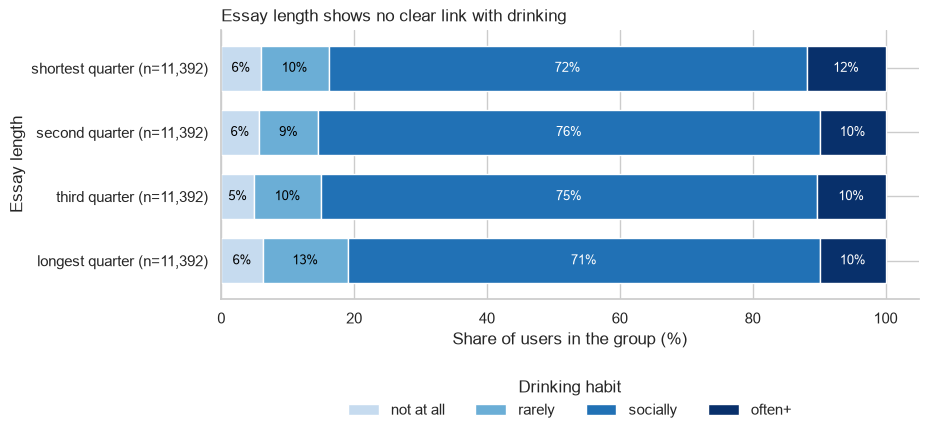

In [25]:
# Rank first so that users with equal word counts still split into four equal groups
df_explore["essay_length"] = pd.qcut(
    df_explore["essay_words"].rank(method="first"),
    4,
    labels=["shortest quarter", "second quarter", "third quarter", "longest quarter"],
)
plot_drinks_by("essay_length", "Essay length shows no clear link with drinking")

### 5.6 Findings

1. **Imbalance.** 73% of users say they drink socially. Accuracy would be misleading, so macro F1 is the main score.
2. **Who is in the data.** Half of users are aged 26 to 37, about 60% are men, about half live in San Francisco and 93% are single. Results describe this group, as noted in Sections 1 and 2.
3. **Missing data.** `offspring`, `diet` and `pets` are the most incomplete fields, and only about one in five users gave an income. Imputation and any dropped fields are decided in Section 7, using training data only.
4. **Strongest links with drinking.** Drug use and smoking, followed by age. Sex and essay length show little link.
5. **Caution.** Some groups are small, for example users who use drugs often, so their shares are uncertain. These are descriptions, not proof, until tested in Section 6.
6. **For the models.** Lifestyle fields look useful. Essay length does not. Whether essay content carries signal is the open question for Sections 8 to 10.

## 6. Statistical Analysis and Hypothesis Testing

Tests a small number of questions chosen in advance, with effect sizes and corrections for multiple comparisons.

### 6.1 Hypotheses

Five hypotheses are stated here, before any test is run. Each asks whether a field is related to the drinking habit. Every test uses the **training set only**.

* **H1. Drug use.** Null: drug use and drinking habit are unrelated. Test: chi square test of independence, because both are categories.
* **H2. Smoking.** Null: smoking and drinking habit are unrelated. Same test.
* **H3. Sex.** Null: sex and drinking habit are unrelated. Same test. This one is included for fairness, not because we expect a large effect.
* **H4. Age.** Null: the average age is the same in all four drinking groups. Test: a Welch type test of averages, which does not need equal spread in each group, followed by Tukey pairwise comparisons.
* **H5. Essay length.** Null: the average essay length is the same in all four drinking groups. Same test, applied to the logarithm of the word count, because essay length is very skewed. Users who wrote no essay are left out of this test, since writing nothing is a different behaviour from writing a short essay. A check that includes them follows the main results.

**Rules.** The significance level is 5%. Five tests are run, so p values are adjusted with the Bonferroni correction. Each result is reported with an effect size and a 95% interval, because with 45,568 users even tiny differences become significant.

**Limits.** These hypotheses came from the patterns seen in Section 5, using the same training data, so the p values are likely to look better than they would on fresh data. Users who left a field blank are left out of that test, and blanks may not be random. Results describe association, not cause.

### 6.2 Tests and assumptions

The two helper functions below run one test each. `chi_square_test` compares the counts in a table of the field against the drinking habit. `mean_difference_test` compares the average of a number across the four drinking groups.

**Assumptions.** Users are treated as independent observations. The chi square test needs an expected count of at least 5 in most cells, which the results table checks. The test of averages does not need equal spread, but it works best when the data is not extremely skewed, so the skew is checked before and after the logarithm for essay length.

In [26]:
# Tests use the training set only
df_tests = df_train.copy()

# Essay length is very skewed, so tests use the logarithm of the word count.
# Users with no essay have a word count of zero, so they become blank here and are left out of H5.
word_count = df_tests[ESSAY_COLUMNS].fillna("").agg(" ".join, axis=1).str.split().str.len()
df_tests["essay_log_words"] = np.log(word_count.where(word_count > 0))
df_tests["essay_log_words_all"] = np.log1p(word_count)  # used only for the check after the main results

# Skew close to zero means a roughly symmetric shape
print(f"Skew of age:                          {df_tests['age'].skew():.2f}")
print(f"Skew of word count:                   {word_count.skew():.2f}")
print(f"Skew of log of word count (H5 users): {df_tests['essay_log_words'].skew():.2f}")

# Average and spread of age in each drinking group
print()
print(df_tests.groupby(TARGET)["age"].agg(["count", "mean", "std"]).round(1).to_string())

Skew of age:                          1.26
Skew of word count:                   3.92
Skew of log of word count (H5 users): -1.41

              count  mean   std
drinks_level                   
not at all     2614  35.5  12.1
often+         4765  30.3   7.7
rarely         4766  34.3  10.9
socially      33423  32.2   9.1


In [27]:
def chi_square_test(data, column):
    """Test whether `column` is related to the drinking habit, using users who answered `column`."""
    answered = data.dropna(subset=[column])
    table = pd.crosstab(answered[column], answered[TARGET])
    chi2, p_value, _, expected = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (len(answered) * (min(table.shape) - 1)))
    return {"users": len(answered), "p_value": p_value, "effect_size": cramers_v, "smallest_expected": expected.min()}


def mean_difference_test(data, column):
    """Test whether the average of `column` differs between drinking habits. Spread may differ between groups."""
    answered = data.dropna(subset=[column])
    groups = [group[column] for _, group in answered.groupby(TARGET)]
    p_value = stats.alexandergovern(*groups).pvalue

    # Effect size: the share of the total variation that is explained by the drinking group
    grand_mean = answered[column].mean()
    between_groups = sum(len(group) * (group.mean() - grand_mean) ** 2 for group in groups)
    total = ((answered[column] - grand_mean) ** 2).sum()
    return {"users": len(answered), "p_value": p_value, "effect_size": between_groups / total, "smallest_expected": np.nan}


def show_p(p_value):
    """Write a p value for reading. Very small values are shown as a bound."""
    if pd.isna(p_value):
        return ""
    return "below 0.001" if p_value < 0.001 else f"{p_value:.3f}"

In [28]:
test_plan = [
    ("H1 drug use", chi_square_test, "drugs"),
    ("H2 smoking", chi_square_test, "smokes"),
    ("H3 sex", chi_square_test, "sex"),
    ("H4 age", mean_difference_test, "age"),
    ("H5 essay length", mean_difference_test, "essay_log_words"),
]

rows = []
for name, test_function, column in test_plan:
    result = test_function(df_tests, column)
    rows.append({"hypothesis": name, "test": test_function.__name__, **result})
results = pd.DataFrame(rows).set_index("hypothesis")

# Very small p values are shown as "below 0.001"
results.assign(p_value=results["p_value"].map(show_p))

,test,users,p_value,effect_size,smallest_expected
hypothesis,,,,,
H1 drug use,chi_square_test,35315,below 0.001,0.186829,22.444910
H2 smoking,chi_square_test,42720,below 0.001,0.127313,69.921816
H3 sex,chi_square_test,45568,below 0.001,0.035705,1053.275413
H4 age,mean_difference_test,45568,below 0.001,0.016380,NaN
H5 essay length,mean_difference_test,44079,below 0.001,0.001012,NaN


In [29]:
# Check: does including the users who wrote no essay change the answer for H5?
check = mean_difference_test(df_tests, "essay_log_words_all")
print(f"H5 with all users (n={check['users']:,}): effect size {check['effect_size']:.4f}, p value {show_p(check['p_value'])}")

H5 with all users (n=45,568): effect size 0.0004, p value 0.002


### 6.3 Effect sizes and confidence intervals

A p value says whether a difference is likely to be real. It does not say whether it is big enough to matter, so each test gets an effect size. For the chi square tests it is Cramér's V, which runs from 0 (no link) to 1 (perfect link). For the tests of averages it is the share of variation explained by the drinking group, from 0 to 1.

Each effect size gets a 95% interval from resampling the users with replacement, 200 times, with a fixed seed. The age comparison between each pair of drinking groups follows, and then one simple contrast that is easy to say aloud: how often drug users drink often compared with users who never use drugs.

In [30]:
def effect_size_interval(test_function, column):
    """95% interval for the effect size, found by resampling users with replacement."""
    sizes = []
    for run in range(N_BOOTSTRAPS):
        resample = df_tests.sample(frac=1, replace=True, random_state=RANDOM_STATE + run)
        sizes.append(test_function(resample, column)["effect_size"])
    return np.percentile(sizes, [2.5, 97.5])


intervals = {name: effect_size_interval(function, column) for name, function, column in test_plan}
results["effect_low"] = [intervals[name][0] for name in results.index]
results["effect_high"] = [intervals[name][1] for name in results.index]

results[["effect_size", "effect_low", "effect_high"]].round(3)

,effect_size,effect_low,effect_high
hypothesis,,,
H1 drug use,0.187,0.179,0.196
H2 smoking,0.127,0.121,0.135
H3 sex,0.036,0.028,0.044
H4 age,0.016,0.014,0.019
H5 essay length,0.001,0.000,0.002


In [31]:
# Which pairs of drinking groups differ in age? Tukey compares every pair.
age_by_group = df_tests.dropna(subset=["age"]).groupby(TARGET)["age"]
labels = list(age_by_group.groups)
tukey = stats.tukey_hsd(*[group for _, group in age_by_group])

pairwise_p = pd.DataFrame(tukey.pvalue, index=labels, columns=labels)
pairwise_p = pairwise_p.where(~np.eye(len(labels), dtype=bool))  # blank out a group compared with itself
print("Tukey p values for age, pair by pair")
print(pairwise_p.map(show_p).to_string())

print("\nAverage age in each group")
print(age_by_group.mean().round(1).to_string())

Tukey p values for age, pair by pair
             not at all       often+       rarely     socially
not at all               below 0.001  below 0.001  below 0.001
often+      below 0.001               below 0.001  below 0.001
rarely      below 0.001  below 0.001               below 0.001
socially    below 0.001  below 0.001  below 0.001             

Average age in each group
drinks_level
not at all    35.5
often+        30.3
rarely        34.3
socially      32.2


In [32]:
# One easy to state contrast: how often do heavy drug users drink often, against users who never use drugs?
heavy_users = df_tests.loc[df_tests["drugs"] == "often", TARGET].eq("often+")
never_users = df_tests.loc[df_tests["drugs"] == "never", TARGET].eq("often+")

share_heavy, share_never = heavy_users.mean(), never_users.mean()
difference = share_heavy - share_never
standard_error = np.sqrt(
    share_heavy * (1 - share_heavy) / len(heavy_users) + share_never * (1 - share_never) / len(never_users)
)
low, high = difference - 1.96 * standard_error, difference + 1.96 * standard_error

print(f"Drink often: {share_heavy:.1%} of users who use drugs often (n={len(heavy_users):,})")
print(f"Drink often: {share_never:.1%} of users who never use drugs (n={len(never_users):,})")
print(f"Difference: {difference * 100:.1f} percentage points (95% interval {low * 100:.1f} to {high * 100:.1f})")

Drink often: 43.7% of users who use drugs often (n=323)
Drink often: 6.7% of users who never use drugs (n=28,908)
Difference: 37.0 percentage points (95% interval 31.6 to 42.4)


### 6.4 Multiple comparison correction

Five tests were run, so the chance that at least one is a false positive is higher than 5%. The Bonferroni correction multiplies each p value by the number of tests, up to a maximum of 1, and keeps the overall false positive rate at 5%. It is simple and slightly cautious. The size labels below are a rough guide based on common conventions, not a rule.

In [33]:
results["adjusted_p"] = (results["p_value"] * len(results)).clip(upper=1)
results["significant"] = results["adjusted_p"] < ALPHA

# Rough guide for describing the size of an effect
EFFECT_LIMITS = {"chi_square_test": [0.1, 0.3, 0.5], "mean_difference_test": [0.01, 0.06, 0.14]}
SIZE_LABELS = ["negligible", "small", "medium", "large"]


def effect_label(test_name, value):
    return SIZE_LABELS[sum(value >= limit for limit in EFFECT_LIMITS[test_name])]


results["size"] = [effect_label(row["test"], row["effect_size"]) for _, row in results.iterrows()]

summary = results[["users", "adjusted_p", "significant", "effect_size", "effect_low", "effect_high", "size"]]
summary.assign(adjusted_p=summary["adjusted_p"].map(show_p)).round(3)

,users,adjusted_p,significant,effect_size,effect_low,effect_high,size
hypothesis,,,,,,,
H1 drug use,35315,below 0.001,True,0.187,0.179,0.196,small
H2 smoking,42720,below 0.001,True,0.127,0.121,0.135,small
H3 sex,45568,below 0.001,True,0.036,0.028,0.044,negligible
H4 age,45568,below 0.001,True,0.016,0.014,0.019,small
H5 essay length,44079,below 0.001,True,0.001,0.000,0.002,negligible


### 6.5 Findings

1. **Drug use and smoking show the clearest links with drinking.** Both are significant after correction, with small effect sizes by the rough guide (Cramér's V of 0.19 and 0.13). Among users who use drugs often, 43.7% drink often, against 6.7% of users who never use drugs. The difference is 37.0 percentage points (95% interval 31.6 to 42.4), although only 323 users report using drugs often.
2. **Age differs between drinking groups, with a small effect.** The drinking group explains about 1.6% of the variation in age. Users who drink often are youngest on average (30.3 years) and users who do not drink at all are oldest (35.5). Tukey comparisons show that every pair of groups differs.
3. **Sex and essay length are detectable but negligible.** Both pass the corrected test, but their effect sizes are tiny: Cramér's V of 0.036 for sex, and 0.1% of the variation for essay length among users who wrote at least one essay. With this many users, very small differences are detectable. This says any difference is very small, not that there is none.
4. **Assumptions held, with one weak spot.** Every expected count in the chi square tables is at least 22, well above the minimum of 5. For essay length, the logarithm changed the skew of the word count from 3.92 to -1.41 once the 1,489 users with no essay were left out. That is better but not fully symmetric, though the sample is large enough for the test of averages to be reliable. Including those users gives the same conclusion (effect size 0.0004, still negligible).
5. **What this means for modelling.** Drug use, smoking and age are worth including as inputs. Sex and essay length alone add almost nothing. Every effect here is small, so each field alone carries limited information. Whether combining fields and essay content does better is tested in Sections 8 to 10.
6. **Cautions.** The hypotheses were chosen after exploring the same data, users who left a field blank are excluded from its test (23% for `drugs`), and these are associations, not causes.

## 7. Feature Engineering and Preprocessing

Builds features and preprocessing steps inside pipelines, fitted on training data only.

### 7.1 Structured features

The fields that become inputs are listed first, so the plan is visible in one place. They were chosen from what Sections 2 to 6 showed.

**Used as inputs**
* Numbers: age, height, number of languages spoken, number of essays answered and essay length.
* Yes or no flags: income answered, and wrote no essay.
* Categories: sex, status, smoking, drug use, body type, diet type, education level, education status, job, children, pets and location.

**Never used as inputs**
* `drinks`, because it is the target.
* `orientation`, `religion` and `ethnicity`, as decided in Section 2.
* `last_online`, because a new user has no activity record.
* The essay text, which is handled in Section 8.
* `sign`, which is kept out of the first models and tested on its own in Section 10.

**New fields built from existing ones.** Wide fields are reduced to what matters.
* `diet_type` drops the strictness word, so "mostly vegetarian" and "strictly vegetarian" both become "vegetarian". This cuts 18 levels to 6.
* `education_level` and `education_status` split the 32 education answers into what the user studied, such as college or masters, and where they are, such as graduated or dropped out.
* `languages_count` is the number of languages in `speaks`, which replaces thousands of different text values.
* `income_answered` records whether a user gave an income. The amounts are dropped because about 80% are missing.

These rules are fixed and learn nothing from the data, so they are safe to apply to any profile.

In [34]:
# Which fields become inputs. Every other field is left out, as explained above.
NUMERIC_FEATURES = ["age", "height", "languages_count", "essays_answered", "essay_log_words"]
FLAG_FEATURES = ["income_answered", "wrote_no_essay"]
CATEGORY_FEATURES = [
    "sex", "status", "smokes", "drugs", "body_type", "diet_type",
    "education_level", "education_status", "job", "offspring", "pets", "location",
]
ALL_FEATURES = NUMERIC_FEATURES + FLAG_FEATURES + CATEGORY_FEATURES

# Answers used by fewer than this share of training users are grouped into one "infrequent" level
MIN_LEVEL_SHARE = 0.005

In [35]:
def group_by_keyword(series, rules):
    """Label each value with the first rule whose keyword it contains. Blank values stay blank."""
    labels = pd.Series(np.nan, index=series.index, dtype="object")
    for keyword, label in rules:
        matches = series.str.contains(keyword, regex=False, na=False) & labels.isna()
        labels[matches] = label
    return labels


# Each rule is (keyword to look for, label to give). The first matching rule wins.
DIET_RULES = [
    ("vegetarian", "vegetarian"), ("vegan", "vegan"), ("kosher", "kosher"),
    ("halal", "halal"), ("anything", "anything"), ("other", "other"),
]
EDUCATION_LEVEL_RULES = [
    ("high school", "high school"), ("year college", "two year college"), ("college/university", "college"),
    ("masters", "masters"), ("ph.d", "phd"), ("law school", "law school"),
    ("med school", "med school"), ("space camp", "space camp"),
]
EDUCATION_STATUS_RULES = [("graduated", "graduated"), ("working on", "working on"), ("dropped out", "dropped out")]


def add_structured_features(df):
    """Add the new fields described above. Fixed rules only, nothing is learned from the data."""
    out = df.copy()
    out["diet_type"] = group_by_keyword(out["diet"], DIET_RULES)
    out["education_level"] = group_by_keyword(out["education"], EDUCATION_LEVEL_RULES)
    out["education_status"] = group_by_keyword(out["education"], EDUCATION_STATUS_RULES)
    # An answer with no status word, such as "college/university", gets the status "unspecified"
    out.loc[out["education"].notna() & out["education_status"].isna(), "education_status"] = "unspecified"
    out["languages_count"] = out["speaks"].str.count(",") + 1
    out["income_answered"] = out["income"].notna().astype(int)
    return out

### 7.2 Features derived from the essays

Three simple measures describe how much a user wrote: the number of the ten prompts they answered, the total length of their essays, and whether they wrote nothing at all. Length is the logarithm of the word count plus one, which keeps zero valid and stops a few very long essays from dominating.

Sections 5 and 6 showed that essay length has almost no link with drinking, so these features are expected to add little. They are included because they are cheap, and the flag keeps users with no text in the data. The content of the essays is handled in Section 8.

The features are built for the **training set only** here. Test features are built once, in Section 12.

In [36]:
def add_essay_features(df):
    """Add simple measures of how much a user wrote. Fixed rules only."""
    out = df.copy()
    essays = out[ESSAY_COLUMNS]
    word_count = essays.fillna("").agg(" ".join, axis=1).str.split().str.len()
    out["essays_answered"] = essays.notna().sum(axis=1)
    out["essay_log_words"] = np.log1p(word_count)
    out["wrote_no_essay"] = (out["essays_answered"] == 0).astype(int)
    return out


X_train = add_essay_features(add_structured_features(df_train))[ALL_FEATURES]
y_train = df_train[TARGET]

print(f"{X_train.shape[0]:,} users x {X_train.shape[1]} input fields")
print(f"Users who wrote no essay: {X_train['wrote_no_essay'].sum():,}")
print(f"Languages spoken: from {X_train['languages_count'].min():.0f} to {X_train['languages_count'].max():.0f}")
print("\nDifferent answers in the new category fields")
print(X_train[["diet_type", "education_level", "education_status"]].nunique().to_string())

45,568 users x 19 input fields
Users who wrote no essay: 1,489
Languages spoken: from 1 to 5

Different answers in the new category fields
diet_type           6
education_level     8
education_status    4


### 7.3 Missing value handling

Blank values are handled in two ways, chosen by the type of field.

* **Categories.** A blank becomes its own level, "missing". A blank can carry meaning, for example a user who skips the question about drugs, so it is kept as information instead of guessed.
* **Numbers.** A blank is replaced with the median of the training set. The table below shows that very few numbers are missing, so a simple median is enough.

Both rules are learned from the training set only. The same medians are later applied to the test set unchanged.

In [37]:
blank_share = (X_train.isna().mean() * 100).round(2)
blank_share = blank_share[blank_share > 0].sort_values(ascending=False)
print("Share of training users with a blank value (%)")
print(blank_share.to_string())

Share of training users with a blank value (%)
offspring           58.28
diet_type           39.21
pets                31.56
drugs               22.50
job                 12.65
education_level      9.54
education_status     9.54
body_type            8.46
smokes               6.25
height               0.08
languages_count      0.06
status               0.02


### 7.4 Encoding and scaling

* **Categories use one hot encoding.** Each answer becomes its own yes or no column. Numbering the answers instead would invent an order, such as "rarely" being smaller than "socially" for a field with no order.
* **Rare answers are grouped.** An answer used by fewer than 0.5% of training users is merged into one "infrequent" column, so very rare answers do not create columns with almost no data.
* **Numbers are scaled** to an average of 0 and a spread of 1. Logistic regression and clustering are sensitive to scale. Tree models do not need it, but it does no harm.
* **Flags pass through** unchanged.

One scikit-learn pipeline holds all of this, with a branch for each type of field. It is fitted on the training set to inspect the result here. In Section 10 it is refitted inside every cross validation fold, so each fold learns its own medians and levels.

In [38]:
numeric_steps = Pipeline([
    ("fill_blanks", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
category_steps = Pipeline([
    ("fill_blanks", SimpleImputer(strategy="constant", fill_value="missing")),
    ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=MIN_LEVEL_SHARE, sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("numbers", numeric_steps, NUMERIC_FEATURES),
    ("categories", category_steps, CATEGORY_FEATURES),
    ("flags", "passthrough", FLAG_FEATURES),
])

# Fit on the training set only, then look at the result
X_train_ready = preprocessor.fit_transform(X_train)
feature_names = preprocessor.get_feature_names_out()
print(f"{X_train.shape[1]} input fields became {X_train_ready.shape[1]} columns")
for branch in ["numbers", "categories", "flags"]:
    count = sum(name.startswith(branch + "__") for name in feature_names)
    print(f"  {branch:<11}{count} columns")

# After scaling, every number should have an average near 0 and a spread near 1
scaled = pd.DataFrame(X_train_ready[:, :len(NUMERIC_FEATURES)], columns=NUMERIC_FEATURES)
print()
print(scaled.describe().loc[["mean", "std"]].round(2).to_string())

19 input fields became 124 columns
  numbers    5 columns
  categories 117 columns
  flags      2 columns

      age  height  languages_count  essays_answered  essay_log_words
mean -0.0    -0.0              0.0             -0.0              0.0
std   1.0     1.0              1.0              1.0              1.0


### 7.5 Leakage check

Four checks confirm that nothing outside the training set influenced the features.

1. The target, the sensitive fields and the other excluded fields are not among the inputs.
2. No profile from the test set is in the data used for fitting.
3. The medians the pipeline learned are the training medians.
4. An answer never seen in training does not break the pipeline, and transforming new data does not change what was learned.

The checks are assertions, so the cell stops with an error if any of them fails.

In [39]:
# Check 1: the target and the excluded fields are not inputs
excluded = [TARGET, TARGET_RAW, "sign", "last_online", *SENSITIVE_COLUMNS, *ESSAY_COLUMNS]
assert not set(ALL_FEATURES) & set(excluded)

# Check 2: no test profile is in the data used for fitting
assert not X_train.index.isin(df_test.index).any()

# Check 3: the learned medians are the training medians
fill_step = preprocessor.named_transformers_["numbers"].named_steps["fill_blanks"]
learned_medians = fill_step.statistics_.copy()
assert np.allclose(learned_medians, X_train[NUMERIC_FEATURES].median())

# Check 4: an unseen answer does not break the pipeline, and transforming does not refit it
probe = X_train.head(1).copy()
probe["job"] = "astronaut"
assert preprocessor.transform(probe).shape[1] == X_train_ready.shape[1]
assert np.allclose(fill_step.statistics_, learned_medians)

print("All four checks passed")
for name, value in zip(NUMERIC_FEATURES, learned_medians):
    print(f"  median {name}: {value:.2f}")

All four checks passed
  median age: 30.00
  median height: 68.00
  median languages_count: 2.00
  median essays_answered: 10.00
  median essay_log_words: 5.78


### 7.6 Summary

* **Inputs.** 19 fields are used: 5 numbers, 2 yes or no flags and 12 categories. After encoding they become **124 columns**: 5 numbers, 117 category columns and 2 flags.
* **New fields.** `diet_type` (6 levels), `education_level` (8), `education_status` (4), `languages_count`, `income_answered`, and three essay measures. 1,489 training users wrote no essay.
* **Missing data.** Blanks in categories become a "missing" level. The most incomplete are `offspring` (58%), `diet_type` (39%), `pets` (32%) and `drugs` (22.5%). Numbers are almost complete, with at most 0.08% blank, so the training median is used.
* **Leakage.** All four checks passed. The pipeline was fitted on the 45,568 training users only. The test set was not used to build or fit anything.
* **Settings to revisit.** The 0.5% cutoff for grouping rare answers is a choice, and it can be tuned with cross validation in Section 10. `sign` and the income amounts were left out on purpose and can be tested later.
* **Not yet done.** The essay text is handled in Section 8, and this pipeline is refitted inside each cross validation fold in Section 10.

## 8. NLP and Text Representation

Turns the essays into numeric representations that later sections reuse.

### 8.1 Text cleaning

The ten essays of each user are joined into one text and cleaned with fixed rules that learn nothing from the data. The rules:

* remove HTML tags such as line breaks, and decode HTML entities;
* remove web links, social media handles, email addresses and phone numbers, as promised in Section 2;
* remove digits and punctuation, and make everything lowercase.

The text is prepared for the training users and for the users with no drinks answer. Together they form `df_fit_unsupervised`, the data used to fit text models. The test set is not touched.

Users who wrote no essay end up with empty text. They stay in the data, but text methods cannot say anything about them, so they are left out of the similarity search in Section 11.

**Finding.** 1,765 users have no text: 1,489 training users and 276 without a drinks answer. The typical user has 296 words after cleaning. No tags or at signs remain, and the word "http" is still present in 6 users, which is too few to matter.

In [40]:
URL_PATTERN = r"https?://\S+|www\.\S+"
EMAIL_PATTERN = r"[\w.+]+@\w+\.[a-z]{2,}"
HANDLE_PATTERN = r"(?<!\w)@\w{3,}"
PHONE_PATTERN = r"\(?\d{3}\)?[\s.]\d{3}[\s.]\d{4}"


def clean_text(text):
    """Turn raw essay text into plain lowercase words. Fixed rules only."""
    text = re.sub(r"<[^>]+>", " ", text)  # HTML tags such as line breaks
    text = html.unescape(text)  # entities such as &amp;
    for pattern in (URL_PATTERN, EMAIL_PATTERN, HANDLE_PATTERN, PHONE_PATTERN):
        text = re.sub(pattern, " ", text, flags=re.IGNORECASE)  # personal details
    text = text.lower().replace("'", "")  # "don't" becomes "dont"
    text = re.sub(r"[^a-z ]", " ", text)  # letters only
    return " ".join(text.split())


raw_texts = df_fit_unsupervised[ESSAY_COLUMNS].fillna("").agg(" ".join, axis=1)
clean_texts = raw_texts.map(clean_text)
has_text = clean_texts.str.len() > 0
word_counts = clean_texts.str.split().str.len()

print(f"Users in the text data: {len(clean_texts):,} ({len(df_train):,} training + {len(df_unlabelled):,} without a drinks answer)")
print(f"Users with no text: {(~has_text).sum():,}")
print(f"Median words per user after cleaning: {word_counts.median():.0f}")

# Nothing that looks like markup or contact details should be left
leftover = {"angle bracket": "<", "at sign": "@", "http": "http"}
print("Users with leftovers:", {name: int(clean_texts.str.contains(text).sum()) for name, text in leftover.items()})

Users in the text data: 48,553 (45,568 training + 2,985 without a drinks answer)
Users with no text: 1,765
Median words per user after cleaning: 296
Users with leftovers: {'angle bracket': 0, 'at sign': 0, 'http': 6}


### 8.2 TF-IDF representation

TF-IDF turns each text into a list of numbers, one for every word or word pair in a vocabulary. A word scores high for a user when they use it often and few other users do, and low when it is everywhere, like "the". Each text becomes a long row that is mostly zeros.

**Settings**
* Common English words such as "and" are removed.
* Single words and pairs of words are used, so "san francisco" is one feature.
* A word must appear in at least 10 users, which drops typos and rare names, and in no more than half of the users.
* Only the 20,000 highest scoring words are kept.
* Repeated words count with diminishing weight, so a word said ten times is not ten times as important.

The vocabulary is learned from `df_fit_unsupervised`, which has no test users. These are the settings Section 10 will refit inside each cross validation fold. The table shows the words that most set apart each drinking group from the others, using words only and counts over many users. Common first names from a fixed list are left out of the word lists shown.

**Finding.** The table covers 48,553 users and 20,000 words and word pairs, and only 0.85% of its cells are not zero. The words that stand out are plausible. Users who drink often mention beer, whiskey, bars and drinking, and users who do not drink at all mention sober, spiritual and "dont drink". Part of the signal is therefore users stating their habit directly in their essays. That is a fair signal, since a new user's essays are known, but Section 10 will check how much of a model's score depends on such words.

In [41]:
start = time.time()
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=TFIDF_MIN_DOCS,
    max_df=0.5,
    max_features=TFIDF_MAX_FEATURES,
    sublinear_tf=True,
)
X_tfidf = tfidf.fit_transform(clean_texts)
tfidf_seconds = time.time() - start

terms = tfidf.get_feature_names_out()


def top_terms(weights, count):
    """The terms with the highest weights, leaving out common first names."""
    ranked = np.argsort(weights)[::-1][:count + 30]
    kept = [terms[i] for i in ranked if not set(terms[i].split()) & PERSONAL_NAMES]
    return kept[:count]
filled_share = X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1])
print(f"{X_tfidf.shape[0]:,} users x {X_tfidf.shape[1]:,} words and word pairs, {filled_share:.2%} of cells are not zero")
print(f"Fitted in {tfidf_seconds:.0f} seconds\n")

# Words that most set each drinking group apart from all labelled users
labelled = df_fit_unsupervised[TARGET].notna().to_numpy()
overall_mean = np.asarray(X_tfidf[labelled].mean(axis=0)).ravel()
print("Words that stand out most in each group")
for level in CLASS_ORDER:
    in_group = (df_fit_unsupervised[TARGET] == level).to_numpy()
    group_mean = np.asarray(X_tfidf[in_group].mean(axis=0)).ravel()
    print(f"  {level:<11}{', '.join(top_terms(group_mean - overall_mean, 10))}")

48,553 users x 20,000 words and word pairs, 0.85% of cells are not zero
Fitted in 18 seconds



Words that stand out most in each group
  not at all spiritual, dont drink, sober, drugs, self, relationship, friend, god, dont, computer
  rarely     relationship, computer, nature, learning, healthy, interested, friend, spiritual, self, know


  socially   family, wine, new, city, travel, family friends, sf, dinner, great, drinks
  often+     beer, drinking, whiskey, wine, shit, drink, bar, drunk, bars, sex


### 8.3 Sentence embeddings

An embedding turns a text into a short list of numbers, here 384, so that texts with similar meaning get similar numbers, even when they share no words. "I love hiking" and "trekking is my favorite thing" end up close together, which TF-IDF cannot do.

**Model.** `all-MiniLM-L6-v2`, a small and widely used sentence model. It runs on this computer, so no essay text is sent anywhere. Its weights are downloaded once in the `safetensors` format, which does not run code when loaded.

**Limit.** The model reads about the first 200 words of a text, so for users who wrote a lot, only the beginning counts. The essays are joined in order, so the self summary comes first.

Users with no text get a row of zeros and are left out of any similarity search. Embeddings are normalised to length one, so the dot product of two rows is their cosine similarity. Running the model is deterministic, so no seed is needed, and it takes a couple of minutes.

**Finding.** 48,553 users became 384 numbers each, in a minute or two on the computer used here. The 1,765 users with no text keep rows of zeros. Every real embedding has length 1, as intended.

In [42]:
start = time.time()
embedding_model = SentenceTransformer(EMBEDDING_MODEL)

# Only users with text are embedded. Users with no text keep a row of zeros.
text_embeddings = embedding_model.encode(
    clean_texts[has_text].tolist(),
    batch_size=64,
    normalize_embeddings=True,
    show_progress_bar=False,
)
embeddings = np.zeros((len(clean_texts), text_embeddings.shape[1]))
embeddings[has_text.to_numpy()] = text_embeddings
embedding_seconds = time.time() - start

lengths = np.linalg.norm(embeddings[has_text.to_numpy()], axis=1)
print(f"{embeddings.shape[0]:,} users x {embeddings.shape[1]} numbers each, computed in {embedding_seconds:.0f} seconds")
print(f"Length of each embedding: {lengths.min():.3f} to {lengths.max():.3f} (should be 1)")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

48,553 users x 384 numbers each, computed in 52 seconds
Length of each embedding: 1.000 to 1.000 (should be 1)


### 8.4 Topic modelling

A topic model groups words that tend to appear together into themes. Non negative matrix factorisation (NMF) works on the TF-IDF table and splits it into a small number of topics. Each topic is a list of words, and each user gets a weight for every topic. The number of topics is a choice, set to 8 so each topic can be read and named.

The table shows how strongly each topic appears among users in each drinking group, as an average weight. This links the themes back to the research question about drinking habits.

**Finding.** The topics are readable: San Francisco and the Bay Area (topics 3 and 8), games and media (4), travel, family and dinner (2), and a reflective theme with words such as open, nature and creative (7). Topic 7 is strongest among users who do not drink or drink rarely (1.3 against 0.6 for users who drink often), and topic 2 is strongest among social drinkers (1.2). Topic 5 is the least clear: its top words are a mix of books, art and personal names. Names appear in the text, so common first names are hidden from the word lists shown, and later sections report scores and never display text.

In [43]:
topic_model = NMF(n_components=N_TOPICS, init="nndsvda", random_state=RANDOM_STATE, max_iter=300)
topic_weights = topic_model.fit_transform(X_tfidf)

print("Topics, shown by their top words")
for number, word_weights in enumerate(topic_model.components_, start=1):
    print(f"  Topic {number}: {', '.join(top_terms(word_weights, 8))}")

# Average topic weight for users in each drinking group
topic_names = [f"topic_{number}" for number in range(1, N_TOPICS + 1)]
topic_table = pd.DataFrame(topic_weights[labelled], columns=topic_names)
topic_table[TARGET] = df_fit_unsupervised.loc[labelled, TARGET].to_numpy()
topic_by_group = topic_table.groupby(TARGET).mean().loc[CLASS_ORDER]
print()
print((topic_by_group * 100).round(1).to_string())

Topics, shown by their top words
  Topic 1: dont, really, think, know, ive, say, lot, ill
  Topic 2: new, enjoy, travel, family, wine, dinner, traveling, work
  Topic 3: bay, area, bay area, moved, years, east, sf, moved bay
  Topic 4: games, favorite, shows, books, tv, video, game, video games
  Topic 5: black, art, making, dead, books, men, radiohead, hot
  Topic 6: fun, family, lol, looking, guy, laugh, want, know
  Topic 7: open, relationship, world, nature, looking, art, creative, woman
  Topic 8: san, san francisco, francisco, moved san, moved, city, years, living san

              topic_1  topic_2  topic_3  topic_4  topic_5  topic_6  topic_7  topic_8
drinks_level                                                                        
not at all        1.2      0.7      0.5      1.1      0.7      0.9      1.3      0.4
rarely            1.3      0.8      0.6      1.1      0.6      0.8      1.3      0.4
socially          1.2      1.2      0.7      1.0      0.9      0.8      0.9   

### 8.5 Comparing the representations

The two representations are compared on size and speed, and then on a small test with three invented sentences, so no real profile text is used. Two of the sentences describe the same activity in different words, and the third is about something else. A good representation should rate the first two as more similar to each other than to the third.

**Finding.** TF-IDF has 20,000 columns, takes 100 MB and builds in well under a minute. Embeddings have 384 columns and take 149 MB stored in full. They take longer to build, a minute or two on the computer used here. On the invented sentences, TF-IDF rates the two hiking sentences at 0.00 because they share no words, while embeddings rate them at 0.72 against 0.08 for the unrelated sentence. Embeddings capture meaning and TF-IDF matches words. How they compare on real profiles is tested in Section 11.

In [44]:
# Size and speed
tfidf_memory = (X_tfidf.data.nbytes + X_tfidf.indices.nbytes + X_tfidf.indptr.nbytes) / 1e6
comparison = pd.DataFrame(
    {
        "columns": [X_tfidf.shape[1], embeddings.shape[1]],
        "memory_mb": [round(tfidf_memory), round(embeddings.nbytes / 1e6)],
        "seconds_to_build": [round(tfidf_seconds), round(embedding_seconds)],
    },
    index=["TF-IDF", "sentence embeddings"],
)
print(comparison.to_string())

# Three invented sentences: two about the same activity in different words, one about something else
examples = [
    "I love hiking and camping in the mountains",
    "Trekking through forests and sleeping in a tent is my favorite thing",
    "I work as an accountant at a bank",
]
cleaned_examples = [clean_text(text) for text in examples]
tfidf_scores = cosine_similarity(tfidf.transform(cleaned_examples))
embedding_scores = cosine_similarity(embedding_model.encode(cleaned_examples, normalize_embeddings=True))

print("\nSimilarity between sentences (0 to 1)")
print(f"{'':<42}{'TF-IDF':>8}{'embeddings':>12}")
print(f"{'hiking vs trekking (same meaning)':<42}{tfidf_scores[0, 1]:>8.2f}{embedding_scores[0, 1]:>12.2f}")
print(f"{'hiking vs accountant (different)':<42}{tfidf_scores[0, 2]:>8.2f}{embedding_scores[0, 2]:>12.2f}")

                     columns  memory_mb  seconds_to_build
TF-IDF                 20000        100                18
sentence embeddings      384        149                52

Similarity between sentences (0 to 1)
                                            TF-IDF  embeddings
hiking vs trekking (same meaning)             0.00        0.72
hiking vs accountant (different)              0.00        0.08


### 8.6 Summary

* **Text prepared.** The essays of 48,553 users (45,568 training users and 2,985 without a drinks answer) were cleaned of markup and contact details. 1,765 of them wrote no text.
* **Three representations built.** TF-IDF with 20,000 words and word pairs, sentence embeddings with 384 numbers each, and 8 topics. All were fitted without the test set.
* **What they show.** Words about drinking separate the groups clearly. The topics are readable and differ between groups, for example a reflective theme is strongest among non drinkers and a dinner and travel theme among social drinkers. Embeddings match meaning where TF-IDF only matches words.
* **Cautions.** Part of the signal is people stating their habit directly. Names appear in the text, so text is never displayed and common first names are hidden from the word lists shown. The embedding model reads only about the first 200 words of each user.
* **Settings to revisit.** The TF-IDF settings, the number of topics and the choice of embedding model are all adjustable. Section 10 refits TF-IDF inside each cross validation fold.
* **Next.** Sections 9 and 11 reuse the TF-IDF table and the embeddings.

## 9. User Segmentation and Clustering

Looks for groups of similar users without using the target.

### 9.1 Input features

Segments are built from two kinds of information, so they reflect both what users write and how they live.

* **Text.** The sentence embeddings from Section 8, which capture the meaning of each user's essays. Only users who wrote something can be placed in a segment.
* **Lifestyle.** Age, height, relationship status, smoking, drug use, body type, diet type, education level, job, children and pets.

**Left out on purpose**
* `drinks`, which is never used to build segments. It is only used afterwards to check them.
* `sex` and `location`, so that segments do not simply split users by gender or neighbourhood. Both are examined afterwards, as a fairness check.
* `orientation`, `religion` and `ethnicity`, as decided in Section 2.

The segments are fitted on `df_fit_unsupervised`, which holds the training users and the users with no drinks answer. The test set is not used.

**Finding.** 46,788 users can be placed in segments. The 1,765 users with no text are left out.

In [45]:
LIFESTYLE_NUMERIC = ["age", "height"]
LIFESTYLE_CATEGORY = ["status", "smokes", "drugs", "body_type", "diet_type", "education_level", "job", "offspring", "pets"]
LIFESTYLE_FEATURES = LIFESTYLE_NUMERIC + LIFESTYLE_CATEGORY

# The target, demographic fields and sensitive fields must not be inputs
assert not {"sex", "location", TARGET, TARGET_RAW, *SENSITIVE_COLUMNS} & set(LIFESTYLE_FEATURES)

# Only users with text can be placed in a segment
cluster_users = df_fit_unsupervised[has_text.to_numpy()]
text_block = embeddings[has_text.to_numpy()]

# Reuse the blank handling and encoding from section 7, fitted here on these users
lifestyle_preprocessor = ColumnTransformer([
    ("numbers", numeric_steps, LIFESTYLE_NUMERIC),
    ("categories", category_steps, LIFESTYLE_CATEGORY),
])
lifestyle_features = add_structured_features(cluster_users)[LIFESTYLE_FEATURES]
lifestyle_block = lifestyle_preprocessor.fit_transform(lifestyle_features)

print(f"Users placed in segments: {len(cluster_users):,} (left out, no text: {(~has_text).sum():,})")
print(f"Text block: {text_block.shape[1]} numbers per user")
print(f"Lifestyle block: {lifestyle_block.shape[1]} columns per user")

Users placed in segments: 46,788 (left out, no text: 1,765)
Text block: 384 numbers per user
Lifestyle block: 84 columns per user


### 9.2 Dimensionality reduction

The two blocks have 384 and 84 columns, and many of them move together. PCA finds the main directions in which users differ and keeps only the first few. The result has less noise, and the clustering is faster and more reliable.

The text block is reduced to 20 components and the lifestyle block to 15. The two reduced blocks are then rescaled so that each one counts equally when distances are measured. Without this step, the block with more variation would decide the segments alone.

The reduction and the rescaling are wrapped in one function, `to_cluster_space`, so that the same steps can place new users into segments later.

**Finding.** Twenty text components keep 44% of the variation in the embeddings, and fifteen lifestyle components keep 69% of the variation in the lifestyle answers. Meaning in text is spread over many directions, so a good part is dropped. This is accepted for the sake of stable groups, and the number of components can be tuned.

In [46]:
text_pca = PCA(n_components=TEXT_COMPONENTS, random_state=RANDOM_STATE).fit(text_block)
lifestyle_pca = PCA(n_components=LIFESTYLE_COMPONENTS, random_state=RANDOM_STATE).fit(lifestyle_block)
print(f"Text: {TEXT_COMPONENTS} components keep {text_pca.explained_variance_ratio_.sum():.0%} of the variation")
print(f"Lifestyle: {LIFESTYLE_COMPONENTS} components keep {lifestyle_pca.explained_variance_ratio_.sum():.0%} of the variation")

# Total spread of each reduced block, used to give the two blocks equal weight
text_scale = np.sqrt(text_pca.transform(text_block).var(axis=0).sum())
lifestyle_scale = np.sqrt(lifestyle_pca.transform(lifestyle_block).var(axis=0).sum())


def to_cluster_space(text_part, lifestyle_part):
    """Reduce each block with PCA and weigh the two blocks equally."""
    return np.hstack([
        text_pca.transform(text_part) / text_scale,
        lifestyle_pca.transform(lifestyle_part) / lifestyle_scale,
    ])


X_cluster = to_cluster_space(text_block, lifestyle_block)
print(f"\nClustering input: {X_cluster.shape[0]:,} users x {X_cluster.shape[1]} numbers")

Text: 20 components keep 44% of the variation
Lifestyle: 15 components keep 69% of the variation

Clustering input: 46,788 users x 35 numbers


### 9.3 Choosing the number of clusters

K-means needs the number of groups in advance, so several values are compared with three checks.

* **Inertia** measures how tight the groups are. It always falls as groups are added, so the sign to look for is a bend where it stops falling quickly.
* **Silhouette score** runs from -1 to 1. Above about 0.5 means clear groups, and below 0.25 means weak structure. It is computed on a random sample of 10,000 users for speed.
* **Stability** asks whether the same groups appear with a different random start or on a different 80% of the users. It is measured with the adjusted Rand index, where 1 means identical groups and 0 means no agreement beyond chance.

The choice is the largest number of groups that is still stable and can be described in words.

**Finding.** Separation is weak at every number of groups. The silhouette score is 0.085 for two groups and falls to 0.04 for ten, far below the 0.25 mark, and the inertia chart has no clear bend. Stability is high up to six groups (0.98 for a new seed and 0.97 for a new sample at k = 6) and drops at seven (0.77 and 0.74) and eight (0.64). Six is therefore the largest stable choice. The weak separation means that users form a continuum, not distinct types, so the segments are tendencies and not boxes.

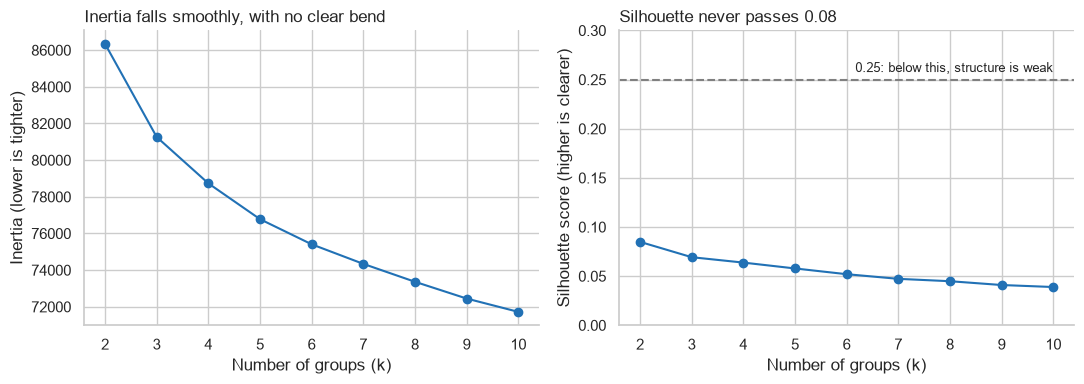

In [47]:
rows = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
    silhouette = silhouette_score(X_cluster, model.labels_, sample_size=SILHOUETTE_SAMPLE, random_state=RANDOM_STATE)
    rows.append({"k": k, "inertia": model.inertia_, "silhouette": silhouette})
k_scores = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(k_scores.index, k_scores["inertia"], marker="o", color=BAR_COLOR)
axes[0].set_title("Inertia falls smoothly, with no clear bend", loc="left")
axes[0].set_xlabel("Number of groups (k)")
axes[0].set_ylabel("Inertia (lower is tighter)")

axes[1].plot(k_scores.index, k_scores["silhouette"], marker="o", color=BAR_COLOR)
axes[1].axhline(0.25, color="grey", linestyle="--")
axes[1].text(10, 0.255, "0.25: below this, structure is weak", ha="right", va="bottom", fontsize=9)
axes[1].set_ylim(0, 0.3)
axes[1].set_title(f"Silhouette never passes {k_scores['silhouette'].max():.2f}", loc="left")
axes[1].set_xlabel("Number of groups (k)")
axes[1].set_ylabel("Silhouette score (higher is clearer)")

sns.despine()
plt.tight_layout()
plt.show()

In [48]:
def stability(k, n_runs=5):
    """Compare the groups for k clusters with groups found from a new seed and from a new 80% of users."""
    reference = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
    rng = np.random.default_rng(RANDOM_STATE)
    new_seed_scores, new_sample_scores = [], []
    for run in range(1, n_runs + 1):
        # Same users, different random start
        other = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE + run).fit(X_cluster)
        new_seed_scores.append(adjusted_rand_score(reference.labels_, other.labels_))
        # Different 80% of users. The new model labels all users, so both sets of labels cover the same people.
        chosen = rng.choice(len(X_cluster), size=int(0.8 * len(X_cluster)), replace=False)
        sample_model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE + run).fit(X_cluster[chosen])
        new_sample_scores.append(adjusted_rand_score(reference.labels_, sample_model.predict(X_cluster)))
    return {"k": k, "new_seed": np.mean(new_seed_scores), "new_80pct_sample": np.mean(new_sample_scores)}


stability_table = pd.DataFrame([stability(k) for k in range(3, 9)]).set_index("k")
stability_table.round(2)

,new_seed,new_80pct_sample
k,,
3,1.00,0.99
4,0.99,0.98
5,0.97,0.97
6,0.98,0.97
7,0.77,0.74
8,0.64,0.64


### 9.4 Fitting and stability

The final model uses the number of groups chosen above. Each user gets a segment number from 1 to N. The numbers are only labels, and their order has no meaning. Segment sizes and the stability of the chosen setting are shown below.

**Finding.** The six segments range from 12% to 22.5% of the 46,788 users, so none is tiny or dominant.

In [49]:
segmenter = KMeans(n_clusters=N_CLUSTERS, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
segment = pd.Series(segmenter.labels_ + 1, index=cluster_users.index, name="segment")

sizes = segment.value_counts().sort_index()
print(pd.DataFrame({"users": sizes, "share_pct": (sizes / sizes.sum() * 100).round(1)}).to_string())
print(f"\nStability for k = {N_CLUSTERS}:")
print(stability_table.loc[N_CLUSTERS].round(2).to_string())

         users  share_pct
segment                  
1         9461       20.2
2        10522       22.5
3         5727       12.2
4         6960       14.9
5         6964       14.9
6         7154       15.3

Stability for k = 6:
new_seed            0.98
new_80pct_sample    0.97


### 9.5 Describing the segments

Each segment is described in four ways. The words it uses most compared with everyone else, the lifestyle answers it over represents (a ratio of 2.0 means twice as common as in the whole data), a few basic numbers, and how its users answer the drinking question.

Drinking habits were never used to build the segments, so they act as a check. Sex was left out too, so its share in each segment is a fairness check. Words are shown as averages over many users, never as individual text. Common first names are left out of the word lists. The plain language names below are an interpretation of these tables, not something the model produced.

**Finding.** The segments can be read in plain language. These names are my interpretation of the tables.

1. **Segment 1, technical men (20%).** 91% are men. Over represented in computer and engineering jobs and in athletic body types. The wording is thoughtful and direct ("think", "really").
2. **Segment 2, social and family minded women (22.5%).** Only 18% are men. Over represented among users with a curvy body type, who want children, and who work in education or are students. Words such as "family", "laugh" and "dancing".
3. **Segment 3, brief profiles (12%).** Defined mostly by blank answers: education, job, smoking and pets are all far more often missing. The writing is informal and short ("lol", "wanna", "ask").
4. **Segment 4, recent arrivals in San Francisco (15%).** Words such as "moved", "san francisco" and "bay area". Technology and sales jobs, athletic builds, 77% men.
5. **Segment 5, culture and nightlife (15%).** Books, shows and music (for example a well known TV comedy and a rock band). Over represented among users who smoke or use drugs sometimes. 64% men.
6. **Segment 6, older professionals (15%).** Average age 49, against 28 to 30 in the other segments. Medicine, health and education jobs, master's degrees, and words about relationships and children. This segment is mostly defined by age.

**Drinking check.** Segment 5 has the highest share of users who drink often (17%), and Segment 6 has the lowest (5%), with 27% drinking rarely or not at all. The other four segments are close to each other, with 8% to 12% drinking often. The segments therefore carry some information about drinking, mainly through Segments 5 and 6.

**Fairness check.** Sex was not used, yet Segments 1 and 2 split almost completely by sex (91% men and 18% men). Writing style and body type act as proxies for sex. This is the proxy risk named in Section 2, and it means these segments partly reflect gender patterns and should not be used to treat users differently.

In [50]:
tfidf_users = X_tfidf[has_text.to_numpy()]
overall_mean = np.asarray(tfidf_users.mean(axis=0)).ravel()

print("Words that stand out most in each segment")
for number in range(1, N_CLUSTERS + 1):
    in_segment = (segment == number).to_numpy()
    segment_mean = np.asarray(tfidf_users[in_segment].mean(axis=0)).ravel()
    print(f"  Segment {number} ({in_segment.sum():,} users): {', '.join(top_terms(segment_mean - overall_mean, 10))}")

Words that stand out most in each segment
  Segment 1 (9,461 users): dont, think, really, ive, say, tall, lot, way, know, probably
  Segment 2 (10,522 users): girl, family, really, dont, laugh, dancing, person, think, favorite, school
  Segment 3 (5,727 users): lol, ask, wanna, phone, smile, sports, good time, want know, fun, guy
  Segment 4 (6,960 users): san, sf, moved, san francisco, francisco, city, bay, area, bay area, new
  Segment 5 (6,964 users): books, black, dead, arrested, arrested development, shows, radiohead, shit, development, punk
  Segment 6 (7,154 users): woman, relationship, share, partner, enjoy, great, kids, healthy, humor, children


In [51]:
# One yes or no column per answer. Blank answers become their own "missing" answer.
answers = pd.get_dummies(add_structured_features(cluster_users)[LIFESTYLE_CATEGORY].fillna("missing")).astype(float)
common_answers = answers.columns[answers.mean() >= 0.05]  # ignore answers used by fewer than 5% of users

print("Lifestyle answers most over represented in each segment (ratio to all users)")
for number in range(1, N_CLUSTERS + 1):
    in_segment = (segment == number).to_numpy()
    ratio = answers.loc[in_segment, common_answers].mean() / answers[common_answers].mean()
    top = ratio.sort_values(ascending=False).head(5)
    print(f"  Segment {number}: " + ", ".join(f"{name} ({ratio[name]:.1f}x)" for name in top.index))

Lifestyle answers most over represented in each segment (ratio to all users)


  Segment 1: job_computer / hardware / software (1.6x), drugs_sometimes (1.4x), job_science / tech / engineering (1.3x), pets_likes dogs and likes cats (1.3x), body_type_athletic (1.3x)
  Segment 2: body_type_curvy (2.2x), offspring_doesn’t have kids, but wants them (1.7x), job_student (1.4x), pets_likes dogs and has cats (1.4x), job_education / academia (1.4x)
  Segment 3: education_level_missing (2.7x), job_missing (2.2x), smokes_missing (2.1x), pets_missing (1.8x), diet_type_missing (1.4x)
  Segment 4: job_science / tech / engineering (1.6x), job_sales / marketing / biz dev (1.6x), pets_likes dogs (1.6x), body_type_athletic (1.5x), offspring_doesn’t have kids (1.4x)
  Segment 5: drugs_sometimes (1.8x), drugs_missing (1.7x), smokes_sometimes (1.7x), smokes_when drinking (1.6x), smokes_missing (1.5x)
  Segment 6: job_medicine / health (1.6x), education_level_masters (1.5x), job_education / academia (1.4x), pets_likes dogs and has cats (1.4x), pets_has dogs (1.3x)


In [52]:
summary = pd.DataFrame({
    "users": segment.value_counts().sort_index(),
    "mean_age": cluster_users.groupby(segment)["age"].mean().round(1),
    "male_pct": (cluster_users["sex"].eq("m").groupby(segment).mean() * 100).round(0),
})
print(summary.to_string())
print(f"\nAll users: mean age {cluster_users['age'].mean():.1f}, male {cluster_users['sex'].eq('m').mean() * 100:.0f}%")

         users  mean_age  male_pct
segment                           
1         9461      30.0      91.0
2        10522      29.2      18.0
3         5727      28.3      70.0
4         6960      29.4      77.0
5         6964      28.5      64.0
6         7154      49.4      52.0

All users: mean age 32.3, male 60%


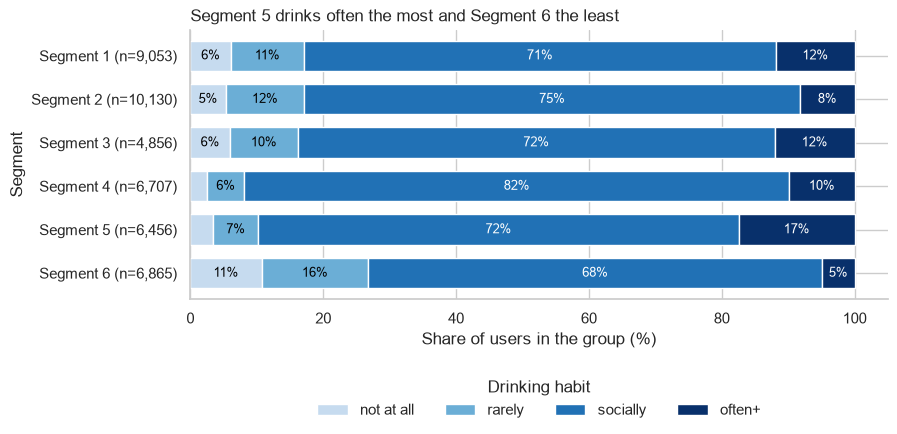

In [53]:
# Training users with a segment and a drinks answer. The segment was built without the drinks answer.
df_explore["segment"] = ("Segment " + segment.astype(str)).reindex(df_explore.index)

# The title names the segments with the highest and lowest share of users who drink often
often_share = df_explore.dropna(subset=["segment"]).groupby("segment")[TARGET].apply(lambda answers: answers.eq("often+").mean())
title = f"{often_share.idxmax()} drinks often the most and {often_share.idxmin()} the least"
plot_drinks_by("segment", title, order=[f"Segment {n}" for n in range(1, N_CLUSTERS + 1)])

### 9.6 Assigning unseen profiles

A segmentation is only useful if a new user can be placed into a segment without refitting anything. `assign_segments` does this with the pieces already fitted: it cleans the text, makes the embedding, applies the lifestyle encoding and the PCA reduction, and picks the nearest segment centre. Users with no text get no segment.

To confirm that the function reproduces the fitted segments, it is run on 500 training users and compared with the segments assigned above. It is applied to the test set only once, in Section 12.

**Finding.** The function put 100% of the 484 users checked into the same segment as before. The other 16 of the 500 had no text and so no segment, as intended.

In [54]:
def assign_segments(df):
    """Place profiles into the fitted segments. Profiles with no text get no segment."""
    texts = df[ESSAY_COLUMNS].fillna("").agg(" ".join, axis=1).map(clean_text)
    has_words = texts.str.len() > 0

    segments = pd.Series(np.nan, index=df.index, name="segment")
    if has_words.any():
        text_part = embedding_model.encode(texts[has_words].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
        lifestyle_part = lifestyle_preprocessor.transform(add_structured_features(df[has_words])[LIFESTYLE_FEATURES])
        segments[has_words] = segmenter.predict(to_cluster_space(text_part, lifestyle_part)) + 1
    return segments


# Check on training users only: the function should reproduce the segments assigned above
check_users = df_train.sample(500, random_state=RANDOM_STATE)
new_segments = assign_segments(check_users)
old_segments = segment.reindex(check_users.index)
has_both = new_segments.notna() & old_segments.notna()
agreement = (new_segments[has_both] == old_segments[has_both]).mean()
print(f"Same segment as before for {agreement:.1%} of {has_both.sum()} users checked")

Same segment as before for 100.0% of 484 users checked


### 9.7 Summary

* **Answer to research question 1.** Partly. The six segments are stable (agreement of 0.97 to 0.98 across new seeds and samples) and can be described in plain words. But separation is weak (silhouette about 0.05), so users form a continuum and the segments describe tendencies, not distinct types.
* **What defines the segments.** Gender related writing and body type (Segments 1 and 2), blank answers (3), place and job (4), culture and substance use (5), and age (6).
* **Link to drinking.** Segment 5 drinks often most and Segment 6 least. This is a check only, since drinking was not used to build the segments. Whether segment membership improves a prediction model is tested in Section 10.
* **Cautions.** Sex was left out of the inputs but is still reflected in two segments. Users with no text are not segmented. The choice of 6 groups and of 20 and 15 PCA components can be revisited.
* **Ready for use.** `assign_segments` places new profiles into the fitted segments. It is applied to the test set once, in Section 12.

## 10. Supervised Learning: Predicting drinks

Compares models for predicting `drinks`, starting with a baseline.

### 10.1 Baseline and set up

All models are compared on the **training set only**, with 5 fold cross validation. In each round, a model is fitted on four fifths of the training users and scored on the fifth it has not seen. The folds are stratified, so each keeps the same share of every drinking group, and a fixed seed makes them repeatable.

Everything that learns from data sits inside the pipeline: the blank handling, the encoders and TF-IDF. They are refitted in every round, so the scoring part never influences them. The scores here are **validation scores**. The test set is not used until Section 12.

**Metric.** Macro F1, which averages the F1 score of the four groups so that the small groups count as much as the big one. Accuracy is shown for reference only. Models also use balanced class weights, which make mistakes on small groups cost more. This lowers accuracy and raises macro F1.

**Baseline.** A model that always predicts the most common answer, "socially".

Each cross validation starts new worker processes, so that a worker never carries memory from an earlier fit. Without this, the parallel library sometimes restarts a worker and prints a harmless warning.

**Training scores** are shown beside validation scores. A large gap means a model is memorising the training data.

**Finding.** The baseline scores a macro F1 of 0.212 and an accuracy of 0.733. Its accuracy looks good only because 73% of users say "socially". Macro F1 shows that it ignores the other three groups completely.

In [55]:
# One table with everything a model may use: the 19 inputs from section 7, the cleaned essay text,
# the segment from section 9 and the embeddings from section 8
EMBEDDING_COLUMNS = [f"embedding_{number}" for number in range(embeddings.shape[1])]
embedding_table = pd.DataFrame(embeddings, index=df_fit_unsupervised.index, columns=EMBEDDING_COLUMNS)

X_model = X_train.copy()
X_model["clean_text"] = clean_texts.reindex(X_model.index)
X_model["segment"] = segment.reindex(X_model.index).map(lambda number: f"Segment {number:.0f}" if pd.notna(number) else np.nan)
X_model = X_model.join(embedding_table)

# The same five folds are used for every model
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"macro_f1": "f1_macro", "accuracy": "accuracy"}

print(f"{X_model.shape[0]:,} training users, {X_model.shape[1]} columns available to the models")

45,568 training users, 405 columns available to the models


In [56]:
def make_tfidf():
    """A fresh TF-IDF with the settings from section 8."""
    return TfidfVectorizer(
        stop_words="english", ngram_range=(1, 2), min_df=TFIDF_MIN_DOCS,
        max_df=0.5, max_features=TFIDF_MAX_FEATURES, sublinear_tf=True,
    )


def make_inputs(structured=False, text=False, embeddings_on=False, segment_on=False):
    """Choose which blocks of information a model gets to see."""
    blocks = []
    if structured:
        blocks.append(("structured", clone(preprocessor), ALL_FEATURES))
    if segment_on:
        blocks.append(("segment", clone(category_steps), ["segment"]))
    if text:
        blocks.append(("text", make_tfidf(), "clean_text"))
    if embeddings_on:
        blocks.append(("embeddings", "passthrough", EMBEDDING_COLUMNS))
    return ColumnTransformer(blocks)


def make_logistic(C=1.0):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=LOGISTIC_MAX_ITER)


def make_model(inputs, classifier):
    return Pipeline([("inputs", inputs), ("model", classifier)])


def cross_validate_fresh(model, data, scoring):
    """Cross validate with new worker processes, so memory grown during an earlier fit is never carried over."""
    get_reusable_executor().shutdown(wait=True)
    return cross_validate(model, data, y_train, cv=cv, scoring=scoring, n_jobs=N_JOBS, return_train_score=True)


cv_scores = {}   # name -> summary scores
fold_scores = {}  # name -> macro F1 of each fold


def evaluate(name, model, data=None):
    """Score a model with cross validation on the training set and keep the result."""
    data = X_model if data is None else data
    start = time.time()
    result = cross_validate_fresh(model, data, scoring=SCORING)
    fold_scores[name] = result["test_macro_f1"]
    cv_scores[name] = {
        "macro_f1": result["test_macro_f1"].mean(),
        "macro_f1_std": result["test_macro_f1"].std(),
        "train_macro_f1": result["train_macro_f1"].mean(),
        "accuracy": result["test_accuracy"].mean(),
    }
    scores = cv_scores[name]
    print(f"{name:<48} validation macro F1 {scores['macro_f1']:.3f} (spread {scores['macro_f1_std']:.3f}) | "
          f"training {scores['train_macro_f1']:.3f} | accuracy {scores['accuracy']:.3f} | {time.time() - start:.0f}s")

In [57]:
evaluate("baseline: most common answer", DummyClassifier(strategy="most_frequent"))
baseline_f1 = cv_scores["baseline: most common answer"]["macro_f1"]

baseline: most common answer                     validation macro F1 0.212 (spread 0.000) | training 0.212 | accuracy 0.733 | 3s


### 10.2 Logistic regression

Logistic regression is the first real model. It is fast, works well with the long sparse tables that TF-IDF creates, and its coefficients can be read. It is a sensible simple model to beat before anything more complicated is tried.

Five versions show which information carries the signal:

* the structured fields alone,
* the essay text alone, as TF-IDF,
* the essay text alone, as sentence embeddings,
* structured fields with TF-IDF,
* structured fields with embeddings.

**Finding.** Both kinds of information help, and the text helps more. The structured fields alone score 0.317, the essay text alone scores 0.351 with TF-IDF and 0.287 with embeddings, and structured fields with TF-IDF score the best at 0.387, against the baseline of 0.212. These gaps are far larger than the spread between folds, about 0.004. TF-IDF beats the embeddings here, probably because words such as "beer" or "sober" matter more for this question than the general meaning of an essay.

Accuracy falls to between 0.36 and 0.53, below the baseline's 0.733. This is expected with balanced class weights: the models give up some accuracy on the big group to catch more of the small ones. The training scores of the TF-IDF models (0.64 to 0.65) are far above their validation scores (0.35 to 0.39), so they overfit.

In [58]:
evaluate("logistic: structured fields", make_model(make_inputs(structured=True), make_logistic()))
evaluate("logistic: TF-IDF text only", make_model(make_inputs(text=True), make_logistic()))
evaluate("logistic: embeddings only", make_model(make_inputs(embeddings_on=True), make_logistic()))
evaluate("logistic: structured + TF-IDF", make_model(make_inputs(structured=True, text=True), make_logistic()))
evaluate("logistic: structured + embeddings", make_model(make_inputs(structured=True, embeddings_on=True), make_logistic()))

logistic: structured fields                      validation macro F1 0.317 (spread 0.004) | training 0.328 | accuracy 0.402 | 5s


logistic: TF-IDF text only                       validation macro F1 0.351 (spread 0.003) | training 0.644 | accuracy 0.492 | 35s


logistic: embeddings only                        validation macro F1 0.287 (spread 0.004) | training 0.314 | accuracy 0.360 | 8s


logistic: structured + TF-IDF                    validation macro F1 0.387 (spread 0.004) | training 0.650 | accuracy 0.527 | 51s


logistic: structured + embeddings                validation macro F1 0.340 (spread 0.004) | training 0.372 | accuracy 0.426 | 28s


### 10.3 Naive Bayes

Naive Bayes is a classic text classifier. It treats every word as independent evidence and adds the evidence up, which is a crude assumption but works surprisingly well on text, and it is very fast. The complement version is designed for imbalanced groups. It is used on the essay text only, since it needs counts or weights that are not negative.

**Finding.** Naive Bayes scores 0.342, slightly below logistic regression on the same text (0.351). It is a reasonable text model, but it does not beat the simpler logistic version.

In [59]:
evaluate("naive bayes: TF-IDF text only", make_model(make_inputs(text=True), ComplementNB(alpha=0.5)))

naive bayes: TF-IDF text only                    validation macro F1 0.342 (spread 0.005) | training 0.488 | accuracy 0.541 | 29s


### 10.4 Tree ensemble

Gradient boosting builds many small decision trees, each one correcting the mistakes of the ones before. Unlike logistic regression, it can find interactions, for example that smoking matters differently at different ages, and it needs no scaling. It is used on the structured fields only. Trees on 20,000 sparse word columns are slow and rarely help.

**Finding.** Gradient boosting scores 0.320 on the structured fields, against 0.317 for logistic regression, a difference well inside the noise. The extra flexibility of trees finds almost nothing more in these fields, so their signal is mostly simple.

In [60]:
evaluate(
    "gradient boosting: structured fields",
    make_model(make_inputs(structured=True), HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
)

gradient boosting: structured fields             validation macro F1 0.320 (spread 0.003) | training 0.405 | accuracy 0.407 | 10s


### 10.5 Tuning with cross validation

Logistic regression has one main setting, `C`. A small `C` means strong regularisation, which keeps the coefficients small and the model simple. A large `C` lets the model follow the training data more closely. The structured plus TF-IDF version is tuned over five values on a log scale, from 0.3 to 30. Each value is scored with 5 fold cross validation inside the training set, on the same folds as the other models. The solver that fits the model stops after a fixed number of iterations, and at large `C` it may need more than the default. The limit is set to 3,000 iterations, and the convergence warnings are left switched on, so any fit that still fails to converge would show a message.

The tuned score is a **validation score** and slightly optimistic, because the setting was chosen using those folds. Two checks follow: whether the best value sits at the edge of the grid, which would mean the search should widen, and whether tuning beat the untuned setting by more than the spread between folds. If not, the simpler setting is kept.

The tuned pipeline is saved as `best_pipeline` and is refitted on the full training set for the final evaluation in Section 12.

**Finding.** The first search, over 0.03 to 1.0, found its best value at the edge of the grid, so it was widened to 0.3 to 30. The best value is now `C = 1.0`, in the interior: validation falls on both sides (0.381 at 0.3, 0.383 at 3). Tuning gains nothing over the default setting, so the default is kept. As `C` grows, the training score climbs from 0.53 to 0.92 while the validation score drops from 0.387 to 0.362, a clear case of overfitting. The chart shows all validation scores so far.

**Convergence check.** With the first limit of 1,000 iterations, five fits stopped early and raised convergence warnings. They were the five folds at `C = 30`, which needed 1,066 to 1,195 iterations. Every other fit converged in 874 iterations or fewer. With the limit raised to 3,000, every fit converges, no warning appears, and the validation scores match the earlier ones, so the choice of `C = 1.0` is confirmed. The warnings were not suppressed.

In [61]:
C_VALUES = [0.3, 1.0, 3.0, 10.0, 30.0]

# One cross validation for each value of C, on the same five folds as every other model.
# Each call has five folds and five workers, so every worker fits exactly one fold.
rows = []
for C in C_VALUES:
    pipeline = make_model(make_inputs(structured=True, text=True), make_logistic(C))
    result = cross_validate_fresh(pipeline, X_model, scoring="f1_macro")
    rows.append({
        "C": C,
        "validation_macro_f1": result["test_score"].mean(),
        "spread": result["test_score"].std(),
        "training_macro_f1": result["train_score"].mean(),
    })
tuning = pd.DataFrame(rows).set_index("C")
print(tuning.round(3).to_string())

best_c = tuning["validation_macro_f1"].idxmax()
untuned = tuning.loc[1.0]
print(f"\nBest C: {best_c} (the grid runs from {min(C_VALUES)} to {max(C_VALUES)})")
if best_c in (min(C_VALUES), max(C_VALUES)):
    print("Warning: the best value is at the edge of the grid, so the grid should be widened")
print(f"Gain over the default C of 1.0: {tuning.loc[best_c, 'validation_macro_f1'] - untuned['validation_macro_f1']:.3f} "
      f"(spread between folds {untuned['spread']:.3f})")

best_pipeline = make_model(make_inputs(structured=True, text=True), make_logistic(best_c))  # unfitted, refitted on the full training set in section 12

      validation_macro_f1  spread  training_macro_f1
C                                                   
0.3                 0.381   0.004              0.531
1.0                 0.387   0.004              0.650
3.0                 0.383   0.003              0.749
10.0                0.375   0.003              0.841
30.0                0.362   0.003              0.921

Best C: 1.0 (the grid runs from 0.3 to 30.0)
Gain over the default C of 1.0: 0.000 (spread between folds 0.004)


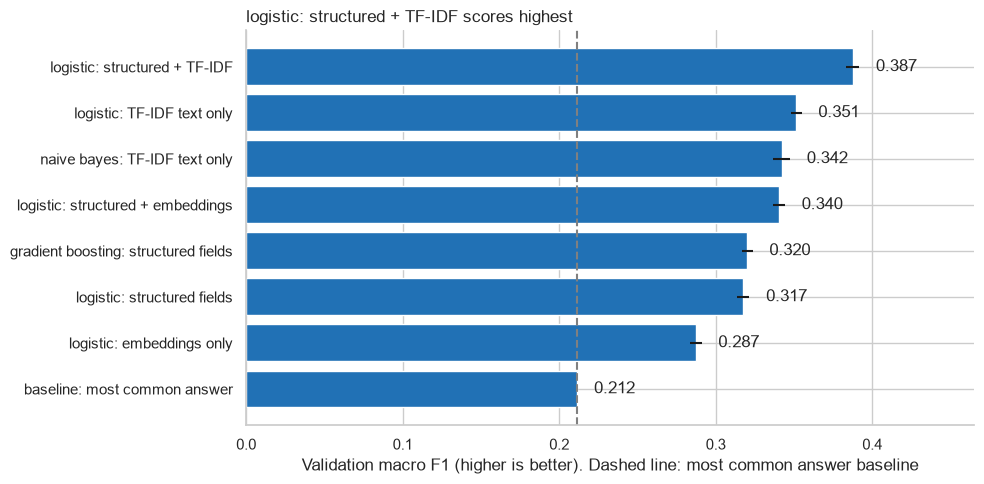

In [62]:
# All validation scores so far, against the baseline
cv_table = pd.DataFrame(cv_scores).T.sort_values("macro_f1")

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(cv_table.index, cv_table["macro_f1"], xerr=cv_table["macro_f1_std"], color=BAR_COLOR)
ax.bar_label(bars, labels=[f"{value:.3f}" for value in cv_table["macro_f1"]], padding=12)
ax.axvline(baseline_f1, color="grey", linestyle="--")
ax.set_xlim(0, cv_table["macro_f1"].max() * 1.2)
ax.set_title(f"{cv_table.index[-1]} scores highest", loc="left")
ax.set_xlabel("Validation macro F1 (higher is better). Dashed line: most common answer baseline")
sns.despine()
plt.tight_layout()
plt.show()

### 10.6 Does clustering help?

The second research question asks whether the segments from Section 9 improve prediction. The segment is added as an extra input to the tuned structured plus TF-IDF model, and the result is compared with the same model without it, on the same five folds. The difference is reported fold by fold, so the spread is visible.

**Caution.** The segments were built without any drinking labels, but from all training users, so the validation folds took part in finding the segment centres. This carries no label information, but it could make the segment version look slightly better than it should. The test set was not part of it.

**Finding.** Adding the segment does not help. The average change in macro F1 is -0.0017, with a spread of 0.0014 between folds, and four of the five folds are slightly lower. The segments were built from the same text and lifestyle information the model already sees, so they add nothing new. Clustering does not improve prediction here.

In [63]:
evaluate("logistic: structured + TF-IDF (tuned C)", clone(best_pipeline))
evaluate(
    "logistic: structured + TF-IDF + segment (tuned C)",
    make_model(make_inputs(structured=True, text=True, segment_on=True), make_logistic(best_c)),
)

difference = fold_scores["logistic: structured + TF-IDF + segment (tuned C)"] - fold_scores["logistic: structured + TF-IDF (tuned C)"]
print(f"\nChange in macro F1 from adding the segment, fold by fold: {np.round(difference, 4).tolist()}")
print(f"Average change {difference.mean():+.4f}, spread between folds {difference.std():.4f}")

logistic: structured + TF-IDF (tuned C)          validation macro F1 0.387 (spread 0.004) | training 0.650 | accuracy 0.527 | 52s


logistic: structured + TF-IDF + segment (tuned C) validation macro F1 0.386 (spread 0.003) | training 0.650 | accuracy 0.525 | 55s

Change in macro F1 from adding the segment, fold by fold: [-0.0022, -0.0037, 0.0007, -0.0021, -0.0013]
Average change -0.0017, spread between folds 0.0014


### 10.7 How much does the text depend on drinking words?

Section 8 showed that users who drink often write words like "beer" and "whiskey". A model could score well mainly by spotting users who say outright that they drink. That is a fair signal, but it says little about whether lifestyle in general predicts drinking.

To measure it, all drinking related words are removed from the text, and two models are scored again with the same settings and folds. The drop in score shows how much of the text signal came from those words.

**Finding.** 47.1% of users mention at least one drinking word. Removing those words lowers the text only model from 0.351 to 0.331, and the structured plus TF-IDF model from 0.387 to 0.372. Drinking words therefore account for a modest part of the signal, and most of it comes from other words. Even without them, text adds about 0.055 over the structured fields alone (0.372 against 0.317).

In [64]:
DRINKING_WORDS = [
    "drink", "drinks", "drinking", "drinker", "drinkers", "drunk", "drunken", "beer", "beers", "wine", "wines",
    "whiskey", "whisky", "bourbon", "vodka", "tequila", "liquor", "alcohol", "alcoholic", "booze", "cocktail",
    "cocktails", "bar", "bars", "pub", "pubs", "brewery", "breweries", "sober", "tipsy", "hangover", "wasted",
]
drinking_pattern = re.compile(r"\b(" + "|".join(DRINKING_WORDS) + r")\b")


def remove_drinking_words(text):
    return " ".join(drinking_pattern.sub(" ", text).split())


X_without_drinking_words = X_model.assign(clean_text=X_model["clean_text"].map(remove_drinking_words))
share_changed = (X_without_drinking_words["clean_text"] != X_model["clean_text"]).mean()
print(f"Users whose text mentioned a drinking word: {share_changed:.1%}\n")

evaluate("logistic: TF-IDF text only, drinking words removed", make_model(make_inputs(text=True), make_logistic()), data=X_without_drinking_words)
evaluate("logistic: structured + TF-IDF, drinking words removed", make_model(make_inputs(structured=True, text=True), make_logistic(best_c)), data=X_without_drinking_words)

Users whose text mentioned a drinking word: 47.1%



logistic: TF-IDF text only, drinking words removed validation macro F1 0.331 (spread 0.002) | training 0.637 | accuracy 0.477 | 35s


logistic: structured + TF-IDF, drinking words removed validation macro F1 0.372 (spread 0.004) | training 0.641 | accuracy 0.514 | 53s


### 10.8 Summary

* **Can drinking be predicted?** Better than chance, but only modestly. The best model, logistic regression on the structured fields plus TF-IDF, reaches a validation macro F1 of 0.387 against the baseline of 0.212. Its accuracy of 0.527 is below the baseline's 0.733 on purpose, because it trades accuracy on the big group for catching the small ones.
* **What carries the signal.** The essay text carries more than the structured fields (0.351 against 0.317), and the two together do best. TF-IDF works better than sentence embeddings (0.351 against 0.287).
* **Model choice.** Simple models match complex ones. Gradient boosting scores 0.320 on the structured fields, no better than logistic regression at 0.317, and Naive Bayes scores 0.342 on text, slightly below logistic regression at 0.351.
* **Does clustering help?** No. Adding the segment changes macro F1 by -0.0017, which is within the noise. This answers the second part of research question 2.
* **Dependence on drinking words.** Removing drinking related words costs about 0.015 to 0.020 of macro F1, so most of the text signal comes from other words.
* **Tuning.** The best value of `C` is 1.0, the default, so tuning changed nothing. A first grid that hit its edge was widened to check. Convergence was also checked: only the five fits at `C = 30` needed more than the first iteration limit, and with the limit raised to 3,000 every fit converges and the choice is unchanged.
* **Cautions.** All scores are validation scores from the training set. The large gap between training (0.65) and validation (0.39) shows overfitting. The segment comparison has a small possible bias, explained in 10.6. The folds are not independent, so the spread is a rough guide. The test set has not been touched.
* **Carried forward.** `best_pipeline` is the structured plus TF-IDF logistic regression with `C = 1.0`. It is refitted on the full training set and scored once on the test set in Section 12.

## 11. Profile Similarity System

Finds profiles similar to a given profile and evaluates the result with proxy measures.

### 11.1 Representations to compare

A similarity system takes a user's essays and returns the users whose essays are most alike. In a dating app this is a content based layer for a new user who has no history yet. Two ways of representing the essays are compared:

* **TF-IDF** matches words. Two users are close when they use the same distinctive words.
* **Sentence embeddings** match meaning. Two users can be close without sharing a single word.

Both were built in Section 8 for the same users, so the comparison is fair. The search covers the 46,788 users with text: the training users and those with no drinks answer. Users with no text cannot be searched. The test set is not part of it.

**Finding.** 46,788 users can be searched. TF-IDF describes each with 20,000 columns and embeddings with 384.

In [65]:
# The users that can be searched: everyone with text in df_fit_unsupervised
corpus_users = cluster_users
corpus_tfidf = X_tfidf[has_text.to_numpy()]
corpus_embeddings = embeddings[has_text.to_numpy()]

# Cosine similarity measures how close two directions are: 1 for identical, 0 for unrelated.
# An exact search over 46,788 users is fast enough, so no approximation is needed.
tfidf_search = NearestNeighbors(metric="cosine", algorithm="brute").fit(corpus_tfidf)
embedding_search = NearestNeighbors(metric="cosine", algorithm="brute").fit(corpus_embeddings)

print(f"{len(corpus_users):,} searchable users")
print(f"TF-IDF: {corpus_tfidf.shape[1]:,} columns | embeddings: {corpus_embeddings.shape[1]} columns")

46,788 searchable users
TF-IDF: 20,000 columns | embeddings: 384 columns


### 11.2 Similarity search

`nearest` returns the most similar users and their similarity scores. When a user from the data is the query, that user is removed from their own results. `similar_to_text` is the entry point for a new user: it cleans the raw text with the same rules as Section 8, turns it into a TF-IDF row or an embedding, and searches.

In [66]:
def nearest(search, query_matrix, own_positions=None, k=N_NEIGHBOURS):
    """Positions and similarity scores of the k most similar users. A user is never their own neighbour."""
    distances, positions = search.kneighbors(query_matrix, n_neighbors=k + 1)
    if own_positions is None:
        return positions[:, :k], 1 - distances[:, :k]

    kept_positions, kept_scores = [], []
    for own, row, row_distances in zip(own_positions, positions, distances):
        not_self = row != own
        kept_positions.append(row[not_self][:k])
        kept_scores.append((1 - row_distances[not_self])[:k])
    return np.array(kept_positions), np.array(kept_scores)


def similar_to_text(raw_text, method="embeddings", k=N_NEIGHBOURS):
    """Find the users whose essays are most similar to a new text. Returns positions and scores."""
    cleaned = clean_text(raw_text)
    if method == "tfidf":
        positions, scores = nearest(tfidf_search, tfidf.transform([cleaned]), k=k)
    else:
        query = embedding_model.encode([cleaned], normalize_embeddings=True)
        positions, scores = nearest(embedding_search, query, k=k)
    return positions[0], scores[0]

### 11.3 Evaluation by held out fields

The data has no match or message outcomes, so there is no direct way to know whether two similar users would like each other. A proxy is used instead. The search uses **essay text only**, so every lifestyle answer is held out. If the nearest users to someone share their lifestyle answers more often than strangers do, the search is finding real similarity.

* 5,000 random users are used as queries, and the 10 most similar other users are found for each.
* **Agreement** is the share of those neighbours who give the same answer as the query, averaged over the queries. Users with a blank answer are skipped.
* **Chance** is the probability that two random users give the same answer. A useful search should beat it. The ratio of the two is the **lift**.
* `sex` and `age_band` are shown as a check on what the search picks up, not as goals. `orientation`, `religion` and `ethnicity` are not examined, as decided in Section 2.

**Finding.** Both methods find neighbours who share lifestyle answers a little more often than chance, but the gaps are small.

* **Embeddings** are above chance on all nine lifestyle fields, by 2.2 to 4.8 percentage points. **TF-IDF** is above chance on eight and slightly below on relationship status.
* The largest ratios to chance are for job (about 1.5 times: 12.6% agreement against 8.2%), children (1.2 to 1.3 times) and education (about 1.1 times).
* **Drinking is barely above chance.** Neighbours share the query's drinking habit 57.5% of the time with TF-IDF and 60.3% with embeddings, against 56.4% by chance.
* Embeddings do better on most fields, mainly drinking, diet, smoking and status. TF-IDF is level with them on job and drugs.
* The average similarity score is 0.13 for TF-IDF neighbours and 0.70 for embedding neighbours. The scores come from different scales and cannot be compared between methods.

**What else the search picks up.** Neighbours are more often the same sex than chance (59.8% with TF-IDF and 56.7% with embeddings, against 51.9%) and more often in the same age band (29.5% and 27.7% against 21.8%). Writing style carries information about sex and age, as Segments 1 and 2 in Section 9 also showed. TF-IDF is slightly more affected than embeddings.

In [67]:
rng = np.random.default_rng(RANDOM_STATE)
query_positions = rng.choice(len(corpus_users), size=SIMILARITY_QUERIES, replace=False)

tfidf_neighbours, tfidf_scores = nearest(tfidf_search, corpus_tfidf[query_positions], own_positions=query_positions)
embedding_neighbours, embedding_scores = nearest(embedding_search, corpus_embeddings[query_positions], own_positions=query_positions)

print(f"{SIMILARITY_QUERIES:,} queries, {N_NEIGHBOURS} neighbours each")
print(f"Average similarity of the neighbours: TF-IDF {tfidf_scores.mean():.2f}, embeddings {embedding_scores.mean():.2f}")

5,000 queries, 10 neighbours each
Average similarity of the neighbours: TF-IDF 0.13, embeddings 0.70


In [68]:
# The answers that were held out from the search
answers = add_structured_features(corpus_users)[["smokes", "drugs", "diet_type", "education_level", "job", "offspring", "pets", "status", "body_type"]].copy()
answers["drinks_level"] = corpus_users[TARGET]
answers["age_band"] = pd.cut(corpus_users["age"], bins=[17, 24, 29, 34, 44, 100], labels=["18 to 24", "25 to 29", "30 to 34", "35 to 44", "45 and over"]).astype("object")
answers["sex"] = corpus_users["sex"]


def agreement(neighbour_positions, field):
    """Average share of neighbours with the same answer as the query. Blank answers are skipped."""
    values = answers[field].to_numpy()
    shares = []
    for own_value, row in zip(values[query_positions], neighbour_positions):
        if pd.isna(own_value):
            continue
        neighbour_values = values[row]
        known = pd.notna(neighbour_values)
        if known.any():
            shares.append((neighbour_values[known] == own_value).mean())
    return np.mean(shares)


def chance(field):
    """Probability that two random users give the same answer."""
    return (answers[field].dropna().value_counts(normalize=True) ** 2).sum()


rows = []
for field in answers.columns:
    chance_level = chance(field)
    tfidf_level = agreement(tfidf_neighbours, field)
    embedding_level = agreement(embedding_neighbours, field)
    rows.append({
        "field": field,
        "chance": chance_level,
        "tfidf": tfidf_level,
        "embeddings": embedding_level,
        "tfidf_lift": tfidf_level / chance_level,
        "embeddings_lift": embedding_level / chance_level,
    })
agreement_table = pd.DataFrame(rows).set_index("field")
agreement_table.round(3)

,chance,tfidf,embeddings,tfidf_lift,embeddings_lift
field,,,,,
smokes,0.664,0.675,0.690,1.017,1.039
drugs,0.704,0.739,0.734,1.048,1.042
diet_type,0.634,0.649,0.660,1.023,1.042
education_level,0.398,0.434,0.438,1.091,1.100
job,0.082,0.126,0.126,1.549,1.544
offspring,0.172,0.212,0.220,1.232,1.276
pets,0.202,0.214,0.224,1.058,1.109
status,0.865,0.859,0.888,0.993,1.027
body_type,0.191,0.209,0.214,1.094,1.122


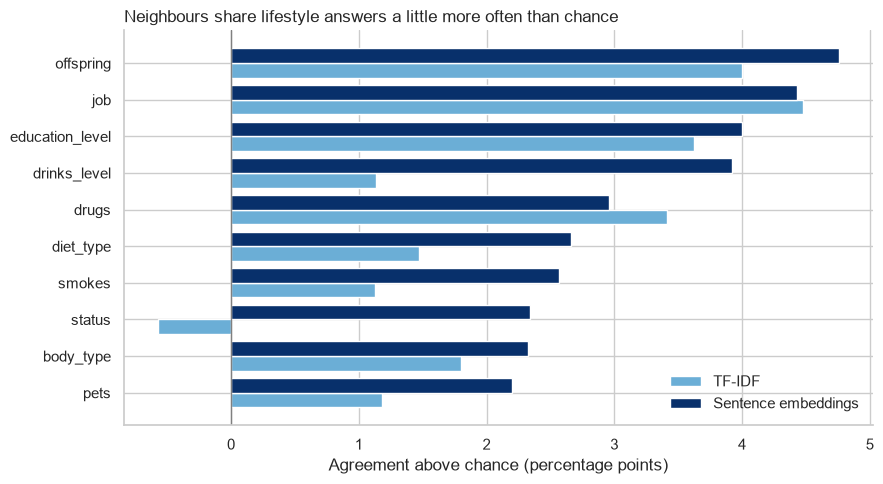

In [69]:
# Points above chance for the lifestyle answers. sex and age_band are left out of the chart as they are not goals.
lifestyle_fields = [field for field in agreement_table.index if field not in ("sex", "age_band")]
points_above_chance = (agreement_table.loc[lifestyle_fields, ["tfidf", "embeddings"]].sub(agreement_table.loc[lifestyle_fields, "chance"], axis=0) * 100)
points_above_chance = points_above_chance.sort_values("embeddings")

fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(points_above_chance))
ax.barh(positions - 0.2, points_above_chance["tfidf"], height=0.4, color=CLASS_COLORS[1], label="TF-IDF")
ax.barh(positions + 0.2, points_above_chance["embeddings"], height=0.4, color=CLASS_COLORS[3], label="Sentence embeddings")
ax.set_yticks(positions)
ax.set_yticklabels(points_above_chance.index)
ax.axvline(0, color="grey", linewidth=1)
ax.set_title("Neighbours share lifestyle answers a little more often than chance", loc="left")
ax.set_xlabel("Agreement above chance (percentage points)")
ax.legend(frameon=False, loc="lower right")
sns.despine()
plt.tight_layout()
plt.show()

### 11.4 Manual review of neighbours

To see what the system returns, one invented profile is searched, so that no real user's text is used. For each method, the 50 most similar users are summarised: the most common answer in six lifestyle fields, as a share of the neighbours who answered, next to the share among all users. No individual profile is shown, and no essay text.

**Finding.** For the invented profile about hiking, craft beer and board games, the two methods return different kinds of neighbours. TF-IDF neighbours more often drink often (18% against 10% for all users), which fits the word "beer" in the profile, since TF-IDF matches words. Embedding neighbours more often drink socially (82% against 73%) and more often work in medicine and health (18% against 7%). The shifts are modest, and neither method gives a clear lifestyle signature. This is one invented profile, so it illustrates the system and is not evidence of a pattern.

In [70]:
invented_profile = (
    "I love hiking and camping, and I spend my weekends exploring the outdoors with my dog. "
    "I am also into craft beer, board games and cooking dinner for friends."
)
REVIEW_NEIGHBOURS = 50
summary_fields = ["job", "drinks_level", "smokes", "drugs", "education_level", "pets"]

# The most common answers among the most similar users, next to the share among all users.
# Shares are of the users who answered. No individual profile is shown.
for method, label in [("tfidf", "TF-IDF"), ("embeddings", "Sentence embeddings")]:
    positions, scores = similar_to_text(invented_profile, method=method, k=REVIEW_NEIGHBOURS)
    neighbours = answers.iloc[positions]
    print(f"{label}: the {REVIEW_NEIGHBOURS} most similar users, similarity {scores.min():.2f} to {scores.max():.2f}")
    for field in summary_fields:
        top = neighbours[field].value_counts(normalize=True).head(2)
        overall = answers[field].value_counts(normalize=True)
        text = ", ".join(f"{answer} {share:.0%} (all users {overall[answer]:.0%})" for answer, share in top.items())
        print(f"  {field:<16}{text}")
    print()

TF-IDF: the 50 most similar users, similarity 0.11 to 0.18
  job             student 15% (all users 10%), sales / marketing / biz dev 15% (all users 9%)
  drinks_level    socially 76% (all users 73%), often+ 18% (all users 10%)
  smokes          no 84% (all users 81%), yes 5% (all users 4%)
  drugs           never 83% (all users 82%), sometimes 17% (all users 17%)
  education_level college 59% (all users 59%), masters 34% (all users 21%)
  pets            likes dogs and likes cats 32% (all users 37%), likes dogs 21% (all users 18%)

Sentence embeddings: the 50 most similar users, similarity 0.62 to 0.72
  job             other 18% (all users 15%), medicine / health 18% (all users 7%)
  drinks_level    socially 82% (all users 73%), not at all 8% (all users 6%)
  smokes          no 86% (all users 81%), sometimes 8% (all users 7%)
  drugs           never 88% (all users 82%), sometimes 12% (all users 17%)
  education_level college 56% (all users 59%), masters 15% (all users 21%)
  pets    

### 11.5 Limits of the evaluation

* **A proxy, not a test of matching.** Agreement on lifestyle answers shows that similar essays tend to go with similar lives. It does not show that two users would get along.
* **No outcomes.** Without matches or messages, the system cannot be scored on what a dating app cares about. A real product would need that data.
* **Only users with text.** Users who wrote nothing cannot be searched or placed.
* **A narrow view of similarity.** The search uses essay text only. Real recommendations would combine it with preferences, location and behaviour.
* **Sameness.** A search that returns users like the query may keep showing people who look alike. The agreement for `sex` and `age_band` shows how strong this tendency is.
* **A sample of queries.** 5,000 users were used as queries, not all 46,788.
* **Privacy.** The system returns similarity scores and lifestyle answers, never essay text. It would need strict controls before use on real users.

### 11.6 Summary

* **Answer to research question 3.** Yes, but only modestly. NLP finds profiles whose lifestyle answers are somewhat more alike than chance, but similarity from essays alone is weak. Most ratios to chance are between 1.0 and 1.3, and the largest is about 1.5 for job.
* **TF-IDF against embeddings.** Embeddings are slightly better on most lifestyle fields, including drinking (60.3% agreement against 57.5% for TF-IDF, with 56.4% by chance), and TF-IDF is level on job and drugs. Embeddings are also somewhat less tied to sex and age. TF-IDF is faster to explain, and embeddings find meaning without shared words.
* **What it means for a product.** A content based layer can give a new user a first set of similar profiles, but it is not enough on its own. It should be combined with structured fields, preferences and, as data arrives, behaviour.
* **Cautions.** The evaluation is a proxy and says nothing about whether two users would match. It used 5,000 queries, covers only users with text, and shows a tendency to return users of the same sex and age group. The search returns scores and lifestyle answers, never essay text.
* **Next.** Section 12 refits the chosen model on the full training set and scores it once on the test set, then compares all results.

## 12. Model Evaluation, Baseline Comparison and Results

Compares all models on the same footing. The test set is used once, at the end.

### 12.1 Metrics

This section uses the test set for the first and only time. The decisions below were fixed in Section 10, before any test result was seen, and nothing is changed afterwards.

**Frozen before testing**
* **Model.** Logistic regression on the structured fields and TF-IDF text, with `C = 1.0` and balanced class weights.
* **Decision rule.** Each user is assigned the drinking group the model finds most likely. No threshold is tuned, because no cost of a wrong answer has been defined for the groups.
* **Main metric.** Macro F1, the average of the F1 score of the four groups, so the small groups count as much as the large one.
* **Baseline.** Always predict the most common training answer, "socially".

**Other numbers reported**
* **Precision** for a group: of the users predicted to be in it, how many truly are.
* **Recall** for a group: of the users truly in it, how many are found.
* **Confusion matrix:** for each true group, where the predictions go.
* **Accuracy,** for reference only, since it rewards ignoring the small groups.

Only the final model and the baseline are scored on the test set. All other models are compared on their validation scores from the training set.

### 12.2 Comparison table

All models from Section 10, with their **validation** scores from 5 fold cross validation on the training set. These are not test scores. The training score is shown to expose overfitting.

**Finding.** The logistic regression on structured fields plus TF-IDF text is first, at a validation macro F1 of 0.387. Tuning it or adding the segment leaves the score unchanged, and the next best models are well behind (0.351 and below). Every model beats the baseline of 0.212. The training scores of the best models (0.65) are far above their validation scores, which is the overfitting noted in Section 10.

In [71]:
comparison = pd.DataFrame(cv_scores).T.sort_values("macro_f1", ascending=False)
comparison = comparison.rename(columns={
    "macro_f1": "validation_macro_f1",
    "macro_f1_std": "fold_spread",
    "train_macro_f1": "training_macro_f1",
    "accuracy": "validation_accuracy",
})
comparison.round(3)

,validation_macro_f1,fold_spread,training_macro_f1,validation_accuracy
logistic: structured + TF-IDF,0.387,0.004,0.650,0.527
logistic: structured + TF-IDF (tuned C),0.387,0.004,0.650,0.527
logistic: structured + TF-IDF + segment (tuned C),0.386,0.003,0.650,0.525
"logistic: structured + TF-IDF, drinking words removed",0.372,0.004,0.641,0.514
logistic: TF-IDF text only,0.351,0.003,0.644,0.492
naive bayes: TF-IDF text only,0.342,0.005,0.488,0.541
logistic: structured + embeddings,0.340,0.004,0.372,0.426
"logistic: TF-IDF text only, drinking words removed",0.331,0.002,0.637,0.477
gradient boosting: structured fields,0.320,0.003,0.405,0.407
logistic: structured fields,0.317,0.004,0.328,0.402


### 12.3 Final test evaluation

The chosen pipeline is refitted on the full training set and predicts the test users once. Test features are built here for the first time, with the same fixed rules as the training features. The baseline always predicts the most common training answer.

The tables show the scores for each group, and the heatmap shows the confusion matrix with each row adding to 100%.

**Finding.** On the 11,393 test users the final model scores a macro F1 of **0.386**, against **0.212** for the baseline, a gain of 0.175. This matches the validation score of 0.387, so the cross validation estimate was reliable and nothing suggests leakage. Accuracy is 0.517, below the baseline's 0.734, as expected with balanced class weights.

The model finds 54% of social drinkers, 53% of users who drink often, 41% of users who drink rarely and 40% of users who do not drink at all. Precision for the three smaller groups is low, 0.17 to 0.28, so most users predicted into a small group are wrong. Mistakes mostly go to the neighbouring group: 34% of users who drink often are predicted "socially", and 34% of non drinkers are predicted "rarely".

In [72]:
# First use of the test set's contents. Nothing below is changed after seeing the result.
needed_columns = ALL_FEATURES + ["clean_text"]

X_test_model = add_essay_features(add_structured_features(df_test))[ALL_FEATURES]
X_test_model["clean_text"] = df_test[ESSAY_COLUMNS].fillna("").agg(" ".join, axis=1).map(clean_text)
y_test = df_test[TARGET]

# Refit the chosen pipeline on the full training set, then predict the test users once
final_model = clone(best_pipeline).fit(X_model[needed_columns], y_train)
predicted = pd.Series(final_model.predict(X_test_model[needed_columns]), index=y_test.index)

# The baseline always predicts the most common training answer
baseline_answer = y_train.value_counts().idxmax()
baseline_predicted = pd.Series(baseline_answer, index=y_test.index)

print(f"Test users: {len(y_test):,} | frozen setting: C = {best_c}")

Test users: 11,393 | frozen setting: C = 1.0


In [73]:
test_macro_f1 = f1_score(y_test, predicted, average="macro")
baseline_test_f1 = f1_score(y_test, baseline_predicted, average="macro", zero_division=0)
validation_f1 = cv_scores["logistic: structured + TF-IDF (tuned C)"]["macro_f1"]

print(f"{'':<34}{'macro F1':>9}{'accuracy':>10}")
print(f"{'Baseline (test)':<34}{baseline_test_f1:>9.3f}{(baseline_predicted == y_test).mean():>10.3f}")
print(f"{'Final model (test)':<34}{test_macro_f1:>9.3f}{(predicted == y_test).mean():>10.3f}")
print(f"{'Final model (validation, section 10)':<34}{validation_f1:>9.3f}")

print("\nScores for each drinking group (test)")
group_report = pd.DataFrame(
    classification_report(y_test, predicted, labels=CLASS_ORDER, output_dict=True, zero_division=0)
).T.loc[CLASS_ORDER + ["macro avg"], ["precision", "recall", "f1-score", "support"]]
group_report["support"] = group_report["support"].astype(int)
print(group_report.round(3).to_string())

                                   macro F1  accuracy
Baseline (test)                       0.212     0.734
Final model (test)                    0.386     0.517
Final model (validation, section 10)    0.387

Scores for each drinking group (test)
            precision  recall  f1-score  support
not at all      0.172   0.395     0.240      653
rarely          0.216   0.405     0.282     1191
socially        0.839   0.541     0.657     8357
often+          0.278   0.532     0.365     1192
macro avg       0.376   0.468     0.386    11393


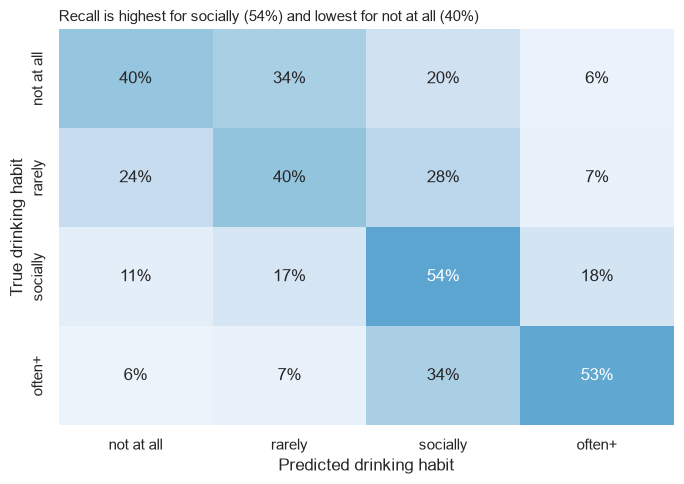

In [74]:
matrix = confusion_matrix(y_test, predicted, labels=CLASS_ORDER, normalize="true")
recall_by_group = pd.Series(np.diag(matrix), index=CLASS_ORDER)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    matrix, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False,
    xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=ax,
)
ax.set_title(f"Recall is highest for {recall_by_group.idxmax()} ({recall_by_group.max():.0%}) and lowest for {recall_by_group.idxmin()} ({recall_by_group.min():.0%})", loc="left", fontsize=11)
ax.set_xlabel("Predicted drinking habit")
ax.set_ylabel("True drinking habit")
plt.tight_layout()
plt.show()

### 12.4 Uncertainty

A test score from 11,393 users is an estimate. To see how much it could vary, the test users are resampled with replacement 1,000 times. Each time, the macro F1 of the final model and the baseline are recomputed, along with the recall of each group, from the predictions already made. Nothing is refitted. The middle 95% of the results gives the range.

Users are treated as independent, which is reasonable here because each row is a different person.

**Finding.** The 95% range for the test macro F1 is 0.376 to 0.397, and for the gain over the baseline it is 0.164 to 0.186. The range is far from zero, so the gain is real, and the validation score of 0.387 sits inside the test range. Recall is least certain for the small groups: 0.356 to 0.435 for "not at all" and 0.502 to 0.562 for "often+".

In [75]:
rng = np.random.default_rng(RANDOM_STATE)
actual = y_test.to_numpy()
model_answers = predicted.to_numpy()
baseline_answers = baseline_predicted.to_numpy()

rows = []
for _ in range(N_TEST_BOOTSTRAPS):
    pick = rng.integers(0, len(actual), size=len(actual))
    model_recall = recall_score(actual[pick], model_answers[pick], labels=CLASS_ORDER, average=None, zero_division=0)
    rows.append({
        "final model": f1_score(actual[pick], model_answers[pick], average="macro"),
        "baseline": f1_score(actual[pick], baseline_answers[pick], average="macro", zero_division=0),
        **{f"recall {group}": value for group, value in zip(CLASS_ORDER, model_recall)},
    })
resamples = pd.DataFrame(rows)
resamples["gain over baseline"] = resamples["final model"] - resamples["baseline"]

ranges = resamples.quantile([0.025, 0.975]).T
ranges.columns = ["low", "high"]
ranges.insert(0, "score", [test_macro_f1, baseline_test_f1] + list(recall_by_group) + [test_macro_f1 - baseline_test_f1])
print("Test scores with 95% ranges")
ranges.round(3)

Test scores with 95% ranges


,score,low,high
final model,0.386,0.376,0.397
baseline,0.212,0.210,0.213
recall not at all,0.395,0.356,0.435
recall rarely,0.405,0.378,0.435
recall socially,0.541,0.530,0.551
recall often+,0.532,0.502,0.562
gain over baseline,0.175,0.164,0.186


### 12.5 Subgroup checks

A good average can hide a group the model fails on. The final model's macro F1 is computed within groups of test users: by sex, by age band, by essay length, and by the segments from Section 9. Essay length bands use the quartile cut points of the training set, so no test information is used to set them. Segments are assigned to test users with `assign_segments`, the first and only use of the segmentation on the test set.

Group scores partly reflect the mix of drinking habits in each group, so the share of users who drink often is shown beside each score. Small groups give noisy scores. Sex is reported only as the two values in the data, and `orientation`, `religion` and `ethnicity` are not examined, as decided in Section 2. This checks for uneven performance, but proxy effects can remain.

**Finding.** Performance is fairly even across most groups, with three weaker spots.

* **Sex.** 0.393 for women and 0.381 for men, a small gap of 0.012.
* **Age.** Users aged 45 and over score lowest among the age bands, at 0.327, against 0.380 to 0.393 for the others. This group is the smallest (1,333 users) and drinks often least (5.6%), which leaves less to learn from.
* **Essay length.** The score rises with the amount of text, from 0.369 for the shortest quarter to 0.397 for the longest.
* **Segments.** From 0.360 for Segment 6, the older professionals, to 0.389 for Segment 5. Users with no text score 0.275 (374 users), because the model has only their structured fields.

This is a check for uneven performance, not a full fairness audit. Sex has only two values in the data, small groups give noisy scores, and proxy effects can remain.

In [76]:
test_words = X_test_model["clean_text"].str.split().str.len()
train_words = X_model["clean_text"].str.split().str.len()
cut_points = train_words.quantile([0.25, 0.5, 0.75]).tolist()

test_results = pd.DataFrame({
    "actual": y_test,
    "predicted": predicted,
    "sex": df_test["sex"],
    "age_band": pd.cut(df_test["age"], bins=[17, 24, 29, 34, 44, 100], labels=["18 to 24", "25 to 29", "30 to 34", "35 to 44", "45 and over"]),
    "essay_length": pd.cut(test_words, bins=[-1] + cut_points + [np.inf], labels=["shortest quarter", "second quarter", "third quarter", "longest quarter"]),
    "segment": assign_segments(df_test).map(lambda number: f"Segment {number:.0f}" if pd.notna(number) else "no text"),
})


def macro_f1_by_group(column):
    """Macro F1 of the final model within each group of test users."""
    rows = []
    for group, members in test_results.groupby(column, observed=True):
        rows.append({
            "group": f"{column}: {group}",
            "users": len(members),
            "often_share": (members["actual"] == "often+").mean(),
            "macro_f1": f1_score(members["actual"], members["predicted"], labels=CLASS_ORDER, average="macro", zero_division=0),
        })
    return pd.DataFrame(rows)


subgroup_scores = pd.concat([macro_f1_by_group(column) for column in ["sex", "age_band", "essay_length", "segment"]]).set_index("group")
subgroup_scores.round(3)

,users,often_share,macro_f1
group,,,
sex: f,4644,0.095,0.393
sex: m,6749,0.111,0.381
age_band: 18 to 24,2041,0.115,0.386
age_band: 25 to 29,3343,0.123,0.380
age_band: 30 to 34,2410,0.110,0.387
age_band: 35 to 44,2266,0.091,0.393
age_band: 45 and over,1333,0.056,0.327
essay_length: shortest quarter,2887,0.120,0.369
essay_length: second quarter,2788,0.099,0.384


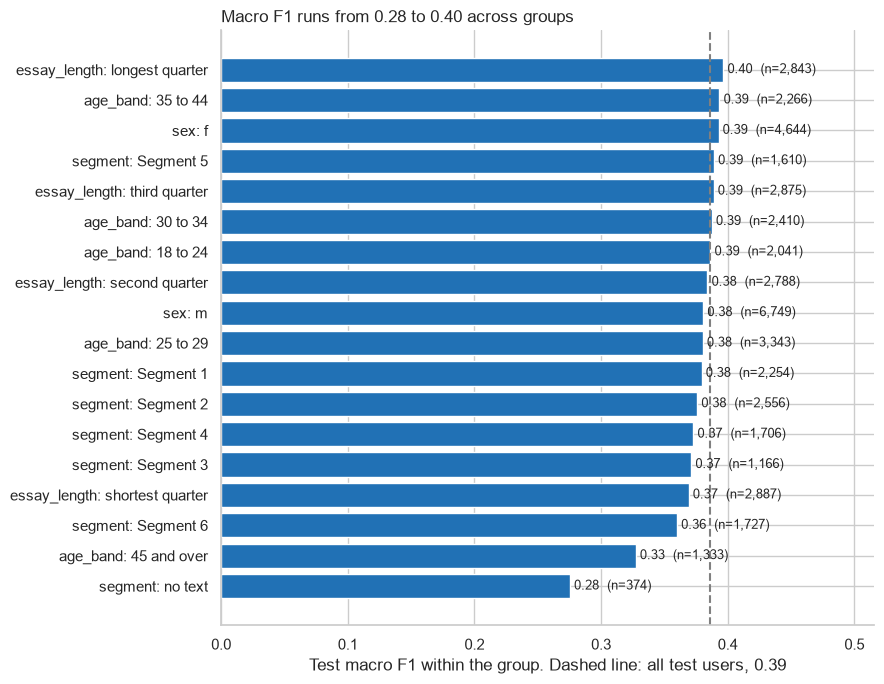

In [77]:
plot_data = subgroup_scores.sort_values("macro_f1")

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(plot_data.index, plot_data["macro_f1"], color=BAR_COLOR)
ax.bar_label(bars, labels=[f"{value:.2f}  (n={users:,})" for value, users in zip(plot_data["macro_f1"], plot_data["users"])], padding=3, fontsize=9)
ax.axvline(test_macro_f1, color="grey", linestyle="--")
ax.set_xlim(0, plot_data["macro_f1"].max() * 1.3)
ax.set_title(f"Macro F1 runs from {plot_data['macro_f1'].min():.2f} to {plot_data['macro_f1'].max():.2f} across groups", loc="left")
ax.set_xlabel(f"Test macro F1 within the group. Dashed line: all test users, {test_macro_f1:.2f}")
sns.despine()
plt.tight_layout()
plt.show()

### 12.6 Results summary

* **Final result (test, 11,393 users).** Macro F1 of 0.386 (95% range 0.376 to 0.397), against 0.212 for the baseline. The gain of 0.175 (0.164 to 0.186) is clearly real. The test score agrees with the validation score of 0.387.
* **In plain terms.** The model finds about half of the social drinkers and of the users who drink often, and about 40% of those who drink rarely or not at all. It is a modest predictor, far better than guessing the most common answer, but wrong for many individuals. Precision for the small groups is only 0.17 to 0.28.
* **Accuracy.** 0.517, below the baseline's 0.734. This is deliberate: the model trades accuracy on the large group for finding the small ones.
* **Best use.** As a soft estimate to fill a missing profile field, shown with its uncertainty. It is not suited to decisions about an individual user.
* **Where it is weaker.** Users aged 45 and over (0.327), users who write little (0.369) and users with no text (0.275). Performance is similar for men and women (0.381 and 0.393) and across the segments (0.360 to 0.389).
* **What this does not show.** The data comes from California profiles of 2011 and 2012, answers are self reported, and the results are associations, not causes. There are no match outcomes, so nothing here says whether the estimate improves recommendations.
* **Use of the test set.** The final model and the baseline were scored once, with the model, decision rule and metric fixed in Section 10 beforehand. Nothing was changed after seeing the result, and rerunning the notebook reproduces the same scores.

## 13. Business Insights and Product Recommendations

Turns the results into practical guidance for a dating product team.

### 13.1 Executive summary

* **The problem.** A new user has no history, so a dating platform has only the profile to work with, and many profiles are incomplete. For example, 58% of users leave out their plans for children and 39% leave out their diet.
* **What works.** The essay text is the most useful part of a profile. A similarity search on sentence embeddings finds users whose lifestyle answers are somewhat more alike than chance: 2.2 to 4.8 points above chance on all nine fields tested, for example 12.6% agreement on job against 8.2% by chance. This is a modest but real signal for a cold start fallback.
* **What is not good enough.** Predicting a user's drinking habit reaches a macro F1 of 0.386 against 0.212 for guessing, which is a real gain, but the model is wrong for many individuals. Precision for the three smaller groups is only 0.17 to 0.28. The user segments are stable but only weakly separated, add nothing to prediction, and partly reflect sex.
* **Recommendation.** Build the central application around profile similarity with explanations. Keep drinking prediction as a clearly labelled educational demonstration, not an automatic profiling feature. Do not use segments to treat users differently, and do not infer sensitive traits.
* **Confidence.** The results were checked on a held out test set. They come from California profiles of 2011 and 2012, with no match outcomes, so any claim that a feature improves matches is an assumption until it is tested on real outcomes.

### 13.2 What the results mean for a product

Each point gives the finding, the section it comes from, and what it means for a product.

1. **Text carries more signal than the structured fields.** Text alone scored a validation macro F1 of 0.351 and the structured fields alone 0.317. Together they scored 0.387 (Section 10). Users who write little are served worse: the test score is 0.369 for the shortest quarter of essays, 0.397 for the longest and 0.275 for users with no text (Section 12). *Meaning:* encouraging users to write a good first essay improves what any text based feature can do.
2. **Similarity from essays works, but weakly.** Neighbours share lifestyle answers 2.2 to 4.8 points more often than chance with embeddings, and the strongest ratios are for job (about 1.5 times chance) and children (1.2 to 1.3 times). For drinking, the agreement is barely above chance (60.3% with embeddings against 56.4%) (Section 11). *Meaning:* a useful starting point for a new user, not a replacement for stated preferences or behaviour.
3. **The two text methods suit different jobs.** Embeddings find more lifestyle agreement and are less tied to sex and age. TF-IDF predicts drinking better (0.351 against 0.287) and its word level weights can be explained (Sections 10 and 11). *Meaning:* embeddings suit ranking, and TF-IDF suits explaining.
4. **Drinking prediction is modest.** Macro F1 of 0.386 (95% range 0.376 to 0.397) against 0.212. It finds about half of social drinkers and of users who drink often, and about 40% of rare and non drinkers. Mistakes mostly go to the neighbouring group, and the precision of the small groups is 0.17 to 0.28 (Section 12). *Meaning:* a rough estimate at best, wrong for many individuals.
5. **Segments are descriptive, not predictive.** They are stable (agreement of 0.97 to 0.98) but weakly separated (silhouette about 0.05), and adding them changes the prediction score by -0.0017 (Sections 9 and 10). *Meaning:* they can summarise a user base, but they do not improve any decision.
6. **Sex shows up even when it is not used.** Segments 1 and 2 are 91% and 18% male although sex was left out, and similarity neighbours are more often the same sex (59.8% with TF-IDF and 56.7% with embeddings, against 51.9%) (Sections 9 and 11). *Meaning:* writing style is a proxy for sex, and leaving a column out does not remove its influence.
7. **Performance is uneven for some users.** Users aged 45 and over score 0.327 and users with no text 0.275, against 0.386 overall (Section 12). *Meaning:* any feature built on these models would work worse for these groups.
8. **The text identifies people.** Essays contain links, handles, emails and phone numbers, and 64% of profiles are unique on six ordinary fields (Sections 2 and 3). No source says that the users agreed to the use of their profiles in research. *Meaning:* privacy is a design requirement, not an extra.

### 13.3 Recommendations

Recommendations are grouped by how well the results support them, and ordered by priority within each group.

**Implement: supported by the results**

1. **Use profile similarity as a cold start fallback.** Rank with sentence embeddings, which found the most lifestyle agreement. Use it only for users with text, and combine it with stated preferences. *Evidence:* Section 11.
2. **Show every similarity result with an explanation.** Explain a match with shared lifestyle answers and the themes both users write about, never with the other user's text. *Evidence:* TF-IDF and topics are explainable, and embeddings found the better matches (Sections 8, 10 and 11). The explanation design itself is an assumption, listed in 13.4.
3. **Encourage a first essay at sign up.** Prompts that ask for a self summary, which 91% of users answer, give the text features something to work with. *Evidence:* Section 12, where scores rise with the amount of text.
4. **Treat a blank answer as unknown.** Do not fill it in silently. Let users confirm or correct any suggestion. *Evidence:* a blank answer can carry meaning, and predictions for individuals are often wrong (Sections 7 and 12).
5. **Build privacy in from the start.** Remove contact details from text before any processing, run models where the data is held, store no essay text in outputs, and return scores and answers in aggregate. *Evidence:* Section 2.

**Keep experimental: promising, but not proven**

1. **Similarity combined with preferences and behaviour.** The text signal is modest alone. It needs testing with real outcomes such as messages and matches, which this data does not contain.
2. **Suggest an answer for a user to confirm.** For example, offer an estimated drinking habit on an optional basis, shown with its uncertainty. Test whether users find it helpful before any wider use. In this project it belongs in the educational demonstration only.
3. **Segments for internal analysis.** They may help describe a user base, but only with a fairness audit first, because they partly reflect sex and age.
4. **Better models.** More data and models tuned for this task might raise the scores, but this project does not show that.

**Do not deploy: not supported by the results, or too risky**

1. **Automatic profiling of drinking or any other lifestyle trait.** The precision for the small groups is only 0.17 to 0.28, and showing a wrong inference about a person to others, or filtering on it, causes real harm. The drinking model is an educational demonstration only.
2. **Inferring orientation, religion or ethnicity.** These were excluded on purpose (Section 2), and essays can reveal them indirectly.
3. **Treating users differently by segment.** The segments partly mirror sex and age, and add nothing to prediction (Sections 9 and 10).
4. **Decisions about an individual user from the models.** Errors are frequent, and larger for users aged 45 and over and users with little or no text.
5. **Showing one user's essay text to another through similarity.** Nothing shows that the users agreed to this. Show scores, shared answers and themes instead.
6. **Calling a similarity score compatibility.** The data has no outcomes, so it measures similar writing and answers, not a good match.

### 13.4 Risks and cautions

**Findings: measured in this project**
* Drinking prediction reaches a macro F1 of 0.386 on the test set, and its precision for the small groups is low.
* Similarity beats chance on lifestyle answers by small margins, and is weak for drinking.
* Segments are stable but weak, and add nothing to prediction.
* Writing style carries sex and age information, and performance is lower for users aged 45 and over, for users who write little and for users with no text.
* Essays contain contact details, and ordinary fields can single people out.

**Assumptions: not tested here**
* That users want recommendations based on similar writing, and that similarity improves matches. The data has no match outcomes.
* That explanations built from shared answers and themes increase trust. This is a design idea, not a result.
* That patterns from California profiles of 2011 and 2012 hold for other places and today.
* That self reported answers are accurate.
* That an optional suggested answer is useful. No user has been asked.

**Risks to manage**
* **Sameness.** Returning users who write alike may narrow who people see. Measure variety, not only agreement.
* **Proxy bias.** Removing a column does not remove its effect. Check results by group after every model change.
* **Over trust.** A confident looking score may lead people to believe a modest model. Show uncertainty and base rates.
* **Misuse.** An inferred lifestyle trait could be used to profile or exclude people. Keep such inference out of the product.
* **Privacy and consent.** Handle every user's text as personal, and do not reuse the original scraped data beyond education and demonstration.

### 13.5 The interactive application and next steps

**Central function.** The planned application demonstrates profile similarity with explainable recommendations. A user types a short invented profile and receives:

* the most similar groups of profiles, ranked with sentence embeddings;
* an explanation of each result: shared lifestyle answers and shared themes, with no essay text from other users;
* the similarity score, with a plain note that it measures similar writing, not compatibility.

**Educational demonstration.** A separate, clearly labelled page shows how the drinking model works: its probabilities for the four groups, the base rates, the confusion matrix and the limits from Section 12. It does not run on real users, stores nothing, and is not presented as a profiling feature.

**Design rules carried over from this notebook**
* Run locally, store no input text, and show aggregate results only.
* Show uncertainty and the baseline next to every prediction.
* Leave out orientation, religion and ethnicity, and say so on the page.
* State the data limits: California, 2011 and 2012, self reported, no match outcomes.

**Next steps**
1. Finish the notebook: conclusions, model card and limitations (Section 14), then future work and the presentation (Section 15).
2. Prepare the repository for sharing: a README that explains how to run the notebook and how long it takes, the pinned environment, and a note that the data file is not included. Nothing is published without explicit approval.
3. Build the application around the central function above, then test whether its explanations are understood by real people.
4. Plan a test with real outcomes, for example whether similarity based suggestions lead to more replies, before any claim about matches.
5. Audit fairness again on any new model or data, by sex, age and amount of text.

## 14. Conclusions, Model Card and Limitations

Answers the research questions and records what the work does and does not show.

### 14.1 Answers to the research questions

**Question 1. User segmentation.** Can meaningful user groups be discovered from profile descriptions, interests and lifestyle information?

*Answer: partly.* Six segments were found from sentence embeddings and lifestyle answers. They are **stable**: the groups agree at 0.98 across new random starts and 0.97 across new samples of users (Section 9). They can be **described in plain words**: technical men, social and family minded women, brief profiles, recent arrivals in San Francisco, culture and nightlife, and older professionals. They are **not well separated**: the silhouette score is about 0.05 at six groups and never passes 0.085 for any number of groups, far below the 0.25 mark for even weak structure. Users form a continuum, so the segments describe tendencies, not distinct types. Two segments split almost completely by sex (91% and 18% men) although sex was not used, and one is mostly an age group.

**Question 2. Supervised learning.** Can drinking preferences be predicted from other profile attributes, and does clustering improve predictive performance?

*Answer: yes, but only modestly, and clustering does not help.* On the test set the final model reaches a macro F1 of 0.386 (95% range 0.376 to 0.397), against 0.212 for always guessing the most common answer (Section 12). It finds about half of the social drinkers and of the users who drink often, and about 40% of rare and non drinkers, but precision for the three small groups is only 0.17 to 0.28. Essay text carries more signal than the structured fields (0.351 against 0.317 in validation), and the two together do best (0.387). Adding the segment to the model changed the validation score by -0.0017, which is within the noise (Section 10).

**Question 3. Profile similarity.** Can NLP identify profiles with similar characteristics, and how do TF-IDF and sentence embeddings compare?

*Answer: yes, but weakly.* The neighbours found from essay text share lifestyle answers more often than chance. With embeddings the margin is 2.2 to 4.8 points on all nine fields tested, and the largest ratio is for job (12.6% agreement against 8.2%). For drinking the margin is small: 60.3% with embeddings, 57.5% with TF-IDF and 56.4% by chance (Section 11). Embeddings were slightly better on most fields and less tied to sex and age. TF-IDF was better for prediction (0.351 against 0.287) and can be explained word by word.

**Overall conclusion.** What people write in a dating profile carries real but limited information about how they live. It is enough to beat guessing and to give a new user a modest first set of similar profiles. It is not enough to infer a person's habits reliably, to define clear user types, or to say that two people would match. Section 13 turns this into product advice: build on similarity with explanations, keep drinking prediction as an educational demonstration, and do not use it to profile users.

### 14.2 Model card

This card covers the three components built in this project. It follows the usual model card headings.

**Model details**
* **Components.**
  1. *Drinking classifier:* logistic regression with balanced class weights and `C = 1.0`, on TF-IDF of the essays (20,000 words and word pairs) and 19 structured fields, which become 124 encoded columns.
  2. *Segmentation:* K-means with six groups on two PCA reduced blocks, sentence embeddings (20 components) and lifestyle answers (15 components), weighted equally.
  3. *Profile similarity:* exact nearest neighbours by cosine similarity, on sentence embeddings from `all-MiniLM-L6-v2` and, for comparison, on TF-IDF.
* **Built.** November 2026, as a portfolio project. Python 3.12, scikit-learn 1.9.1, sentence-transformers 6.3.0. Random seed 42.
* **Status.** An educational demonstration. Not validated for any production use.

**Purpose and intended use**
* To study how profile text and lifestyle answers can help with the cold start problem of a dating platform: grouping users, estimating a missing answer and finding similar profiles.
* To demonstrate honest evaluation, with baselines, uncertainty ranges and subgroup checks.
* Intended users are people learning data science, and reviewers of this portfolio. The planned interactive application uses profile similarity with explanations as its central function, and shows the drinking model on a clearly labelled educational page.

**Prohibited and unsupported uses**
* Automatically profiling users, for example inferring drinking or any other lifestyle trait and showing it to others, or filtering on it.
* Inferring orientation, religion or ethnicity, or any other sensitive trait.
* Treating users differently by segment, or making decisions about an individual from the models.
* Showing one user's essay text to another.
* Describing a similarity score as compatibility or a prediction of a match.
* Use on data from other places or periods without a new evaluation.

**Data**
* A teaching file of 59,946 OkCupid profiles with 31 columns: multiple choice answers and ten short essays.
* Source: the educational dataset by Albert Y. Kim and Adriana Escobedo-Land (2015), in its original version. Their 2021 revision removes location and last online, adds noise to age and shuffles the essays, so this project cannot be repeated on the revised files.
* Profiles were last online between June 2011 and July 2012. 99.8% are in California, about half mention San Francisco, and `sex` has two values, male and female.
* The data was scraped from public profiles in 2012 and shared for teaching with OkCupid's permission, on the condition that it remains public. No source states a licence or says that the users agreed. It is used for education only and is not redistributed.
* Split: 45,568 training users and 11,393 test users, stratified on the target with seed 42. 2,985 users without a drinks answer were used only for unsupervised work.

**Methods in brief**
* Fixed cleaning rules, then all fitting on training data only inside pipelines.
* Target: `drinks` grouped into four levels, with the rare answers "very often" and "desperately" merged into "often+".
* Models compared with 5 fold cross validation on the training set. The test set was used once, for the final model and the baseline.

**Evaluation metrics**
* Classifier: macro F1 (main), with accuracy, and precision and recall for each group.
* Segmentation: silhouette score, and stability measured by the adjusted Rand index.
* Similarity: agreement of neighbours on held out lifestyle answers, against chance.

**Performance (test set, 11,393 users)**
* Macro F1 0.386 (95% range 0.376 to 0.397), against 0.212 for the baseline. Gain 0.175 (0.164 to 0.186).
* Accuracy 0.517, against 0.734 for the baseline. The model gives up accuracy on the large group on purpose.
* Recall: 0.541 for social drinkers, 0.532 for often+, 0.405 for rarely and 0.395 for not at all. Precision for the three small groups: 0.17 to 0.28.
* Segmentation: silhouette about 0.05, stability 0.97 to 0.98.
* Similarity: 2.2 to 4.8 points above chance with embeddings on nine fields, 60.3% agreement for drinking against 56.4% by chance.

**Fairness**
* Orientation, religion and ethnicity were excluded as targets and as inputs. Sex and location were not used for segmentation.
* Test macro F1 is 0.393 for women and 0.381 for men. It is lower for users aged 45 and over (0.327), for users with the shortest essays (0.369) and for users with no text (0.275).
* Sex still shows in the segments (91% and 18% men in two of them) and in the similarity neighbours (same sex 56.7% to 59.8%, against 51.9% by chance), so writing style acts as a proxy.
* This is a check for uneven performance, not a full fairness audit. Sex has two values in the data, small groups give noisy scores, and no attempt was made to examine orientation, religion or ethnicity.

**Privacy**
* Links, handles, emails and phone numbers were removed from the essays before text analysis. No essay text is displayed. Results are aggregate.
* Embeddings were computed on a local computer, with no text sent to any service.
* 64% of profiles are unique on six ordinary fields, so the data cannot be treated as anonymous. The data file is excluded from version control.

**Limitations**
* See Section 14.3 and 14.4.

### 14.3 Why the results are modest

Four results are weaker than one might hope. For each, the **demonstrated** facts are separated from **likely explanations**, which this project did not test, and from what could help.

**Weak cluster separation**
* *Demonstrated.* The silhouette score is about 0.05 at six groups, the inertia curve has no bend, and the groups are stable but overlap.
* *Likely explanations.* Profiles vary smoothly more than they fall into types. K-means looks for round groups of similar size. The 20 text components keep only 44% of the variation in the embeddings. Short, informal essays give noisy embeddings.
* *What could help.* Methods that allow overlapping or uneven groups, a different choice of features, or longer text.

**Modest classification performance**
* *Demonstrated.* Macro F1 is 0.386, and the training score of 0.65 is far above the validation score, so the models overfit. Stronger regularisation did not help, and gradient boosting did no better than logistic regression on the structured fields. Text carries more signal than the structured fields. Removing drinking words costs only 0.015 to 0.020 of macro F1.
* *Likely explanations.* A drinking habit is only weakly tied to what a person writes. The label is self reported and coarse, and the groups overlap, for example "rarely" and "not at all". The small groups have few examples.
* *What could help.* More data, better labels, or features designed for the question. This project does not show that these would work.

**Limited gains from profile similarity**
* *Demonstrated.* Neighbours beat chance by 2.2 to 4.8 points with embeddings, and by less with TF-IDF. Neighbours are more often the same sex and age band than lifestyle twins.
* *Likely explanations.* Essays reflect writing style, interests and age more than they reflect lifestyle answers. The embedding model reads only the first 200 words and was not trained on dating profiles. Agreement on one field is a crude measure of similarity.
* *What could help.* Combining text with structured answers, a model adapted to profiles, and evaluation on real outcomes.

**No real compatibility outcomes**
* *Demonstrated.* The data contains no matches, messages, ratings or any other outcome between users.
* *Consequence.* The similarity system measures alike writing and answers. It cannot show whether two similar users would get along, or whether a recommendation improves a platform. Every statement about compatibility in this project is therefore an assumption.
* *What could help.* A test on real outcomes, run with users' consent and with the privacy safeguards in this notebook.

### 14.4 Demonstrated findings, assumptions and future opportunities

**Demonstrated in this project**
* Essay text beats the structured fields for predicting a drinking habit, and the two together are best. The final model reaches a test macro F1 of 0.386 against 0.212 for the baseline.
* Predictions are wrong for many individuals, especially in the small groups, and are weaker for users aged 45 and over and for users with little or no text.
* Six user segments are stable but weakly separated, add nothing to prediction, and partly reflect sex and age.
* Similarity from essays beats chance on lifestyle answers by small margins. Embeddings are slightly better than TF-IDF for this, and TF-IDF is better for prediction.
* Writing style carries information about sex and age, even when those fields are not used.
* The text holds personal details, and ordinary fields can single people out.

**Assumptions: not tested here**
* That similarity based suggestions improve matches or help users.
* That explanations built from shared answers and themes increase trust.
* That the patterns hold for other places, other platforms and today. The data is from California in 2011 and 2012.
* That self reported answers are accurate.
* That an optional suggested answer would be useful to users.
* That the reasons given in 14.3 are the true causes of the weak results.

**Future opportunities**
* Test similarity with real outcomes and consent, for example an experiment on replies.
* Combine text similarity with structured preferences and behaviour.
* Try methods for overlapping groups, and compare models adapted to profile text.
* Repeat the fairness checks on any new model, and extend them with the help of people affected.
* Build the interactive application described in Section 13, centred on similarity with explanations, and test whether people understand the explanations.

## 15. Future Work and Portfolio Presentation

Records next steps and points to the slide deck.

### 15.1 Future work

These are realistic next steps, ordered from those that can start now to those that need data this project does not have. Each is an idea to test, not a result.

**Better NLP**
* **Use all of the text.** The embedding model reads only about the first 200 words. Embedding each essay separately and combining the results would use everything a user wrote.
* **Try other embedding models.** Compare larger or newer sentence models, and models adapted to informal profile text, with the same agreement test used in Section 11.
* **Keep names out.** Common first names are only hidden from the word lists shown, using a fixed list. A step that removes personal names from the text itself would improve privacy and the topics.
* **Check non English text,** which this project could not measure.

**Preference aware profile similarity**
* **Combine text with stated preferences.** Use text similarity to find candidates, then rank them with what users say they want, such as age range, plans for children and tolerance for smoking.
* **Add variety.** A re ranking step that avoids a list of near copies would address the sameness found in Section 11.
* **Consider both sides.** A good suggestion must suit both people, so scores should be checked in both directions.
* **Learn the weights from outcomes** once outcomes exist, instead of choosing them by hand.

**Stronger fairness evaluation**
* **Measure who is shown to whom.** Check exposure in the similarity results by sex and age, and not only the accuracy of a prediction.
* **Test with changed text.** Swap gendered words or names in an invented profile and see whether the results shift.
* **Look at combinations,** such as sex together with age, with confidence ranges for every group.
* **Involve the people affected** in deciding which harms to check, and monitor results over time.

**Real user feedback**
* **Study the explanations.** Ask people whether the shared answers and themes make a suggestion understandable and trustworthy.
* **Collect opt in feedback** on whether a suggestion was useful.
* **Run a randomised test** on outcomes such as replies and the length of conversations, with consent, and with checks that suggestions do not become less varied or less fair.

**Better prediction, if it is pursued**
* Use an ordered model, since the drinking groups run from least to most.
* Give calibrated probabilities with an honest uncertainty, which is what the educational page needs.
* Choose the decision rule from a stated cost of each kind of mistake, which this project did not have.
* Gather newer, larger data with better labels.

**Engineering**
* Move the reusable steps into tested modules, save the fitted pipelines safely, and speed up the run. As an example, the last clean run took about 16 minutes on the computer used for this project, with five parallel workers. The time will differ on other computers.

### 15.2 The interactive application

The application is future work and has not been built. It would have two parts.

**Profile discovery, the central function.** A user types a short profile, which can be invented, and receives the most similar groups of profiles. Each result comes with an explanation of shared lifestyle answers and shared themes, never another user's text, and a plain note that the score measures similar writing, not compatibility. Ranking uses sentence embeddings, and the explanation uses TF-IDF terms, topics and shared answers.

**Model insights, a separate educational page.** It shows how the drinking model works: its probabilities for the four groups, the base rates, the confusion matrix and the limits from Section 12. It does not run on real users, stores nothing, and is not presented as a profiling feature.

Both parts follow the design rules in Section 13: run locally, store no input text, show aggregate results only, show uncertainty next to every prediction, leave out orientation, religion and ethnicity, and state the data limits.

### 15.3 Presentation outline

**Audience and aim.** A general professional audience that may not include data science specialists. The talk should take about ten minutes. It leads with the answer, uses the notebook's charts, and is honest about what the results do not show.

**Outline**
1. **Title and the answer in one line.** Essays help, modestly; nothing here shows that two people would match.
2. **The business problem.** The cold start problem: a new user has only a profile, and many are incomplete (58% leave out children, 39% diet).
3. **Data and ethics.** What the data is, where it comes from and why the users' consent matters, and what was done about it: no sensitive traits, contact details removed, no text shown.
4. **Method in one picture.** Clean, split once, then three components: segments, a drinking model and profile similarity. Fit on training data only, test set used once.
5. **Question 1, user segments.** Six stable but weakly separated groups. Chart: the drinking habits by segment (Section 9).
6. **Question 2, predicting drinking.** Macro F1 of 0.386 against 0.212, and clustering does not help. Charts: the model comparison (Section 10) and the confusion matrix (Section 12).
7. **Question 3, profile similarity.** Neighbours share answers more often than chance, and embeddings beat TF-IDF on most fields. Chart: agreement above chance (Section 11).
8. **Fairness.** Similar for men and women, weaker for users aged 45 and over and for users with little text, and sex shows up even when unused. Chart: the subgroup scores (Section 12).
9. **Why the results are modest, and what the data cannot show.** No outcomes, so no claim about matches.
10. **Product recommendations.** What to implement, what to keep experimental, and what not to deploy (Section 13).
11. **The planned application.** Profile discovery with explanations as the central function, and a separate educational page. A mock up or screenshot goes here once it exists.
12. **Next steps and what this project shows.** The future work above, and the skills on display: end to end workflow, honest evaluation, uncertainty, fairness and privacy.

**Principles for the slides**
* One message per slide, with the finding as the title.
* Use the notebook's charts, which already state their finding in the title.
* Show numbers with their ranges, and the baseline next to every score.
* Keep an appendix with the model card and the limitations.

### 15.4 Slide deck

The 12 slide presentation is in this repository: [OKCupid_Data_Science_Portfolio_Presentation.pptx](OKCupid_Data_Science_Portfolio_Presentation.pptx). It follows the outline in 15.3 and uses charts from this notebook.